# Bayesian Team-Plan Model
This notebook fits Models A–D to the combined Human-only + mixed + LLM-only dataset, runs the configured validation checks, and generates the 14-round observed-versus-simulated trajectories.

**Run cells from top to bottom.** Start with `PROFILE = "quick"`; switch to `"paper"` for the full validation run.

In [19]:
#!/usr/bin/env python3
"""
Bayesian team-plan model pipeline for the 6-player Name Game.

This is a self-contained, publication-oriented analysis script for the combined
Human-only + mixed Human/LLM + LLM-only tidy dataset.

CORE MODEL
----------
Latent current collective plan G_t in {J, M, N}.
At round 8, observer-type-specific priors are
    q_8(G_J) = 1 - h_t
    q_8(G_M) = q_8(G_N) = h_t / 2,
where t is Human or AI/LLM.

For rounds 9-14, the "reversible team-plan" architecture reconstructs current
plan beliefs from the round-8 baseline prior plus public actions in ONLY the
immediately preceding round. This makes a failed attempted transition reversible
without adding a reversion parameter.

Models A-D:
    A: shared h, shared response curve                     k=4
    B: Human/AI h differ, shared response curve            k=5
    C: shared h, Human/AI response curves differ           k=6
    D: Human/AI h differ, Human/AI response curves differ  k=7

The response curve is parameterized by endpoints:
    p_lo = P(adopt plan-specific M/N action | advantage=-10)
    p_hi = P(adopt plan-specific M/N action | advantage=+20)
with p_hi >= p_lo.

Action categories are J, M, N, Other, including a 26-letter lapse model.

PAPER-READY CHECKS
------------------
1. Strict data integrity checks.
2. Independent NumPy/JAX likelihood agreement.
3. Multistart MLE for A-D + AIC/BIC + boundary diagnostics.
4. Same-parameter-count architecture comparison against cumulative inference.
5. Whole-group stratified cross-validation for all A-D models.
6. Empirical-neighborhood parameter recovery for Model D.
7. A-D model recovery under AIC and BIC.
8. Human one-/two-signal diagnostic under observed histories.
9. Forward parametric predictive simulations and trajectory RMSE.
10. Full 1-14 simulation figure for all A-D models against observed data.

IMPORTANT 1-14 SIMULATION NOTE
------------------------------
The fitted team-plan model begins at the payoff change (round 8). For rounds 1-7,
the script uses a parameter-free established-convention extension: G_J is fixed
with probability 1 and choices are generated only through the fitted lapse rate.
At round 8, beliefs reset to the fitted post-change prior q_8. Thus the figure is
a genuine 1-14 simulation, but parameters h and response curves are fitted only
on rounds 8-14.

Dependencies:
    numpy pandas scipy matplotlib jax

Example:
    python team_plan_paper_pipeline.py \
        --data name_game_combined_human_llm_mixed.csv \
        --out team_plan_paper_outputs \
        --profile paper

For a fast end-to-end code test:
    python team_plan_paper_pipeline.py --profile smoke
"""

from __future__ import annotations

import argparse
import json
import math
import time
import warnings
from dataclasses import dataclass
from functools import lru_cache
from pathlib import Path
from typing import Dict, Iterable, List, Mapping, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
from scipy.optimize import OptimizeResult, minimize
from scipy.special import expit, logit

import matplotlib.pyplot as plt

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
from jax.scipy.special import logsumexp


# =============================================================================
# Constants and configuration
# =============================================================================

MODELS: Tuple[str, ...] = ("A", "B", "C", "D")
N_PARAMETERS: Dict[str, int] = {"A": 4, "B": 5, "C": 6, "D": 7}
PARAM_NAMES: Tuple[str, ...] = (
    "hH", "hA", "p_loH", "p_hiH", "p_loA", "p_hiA", "epsilon"
)
ACTION_NAMES: Tuple[str, ...] = ("J", "M", "N", "Other")
TYPE_NAMES: Tuple[str, ...] = ("Human", "AI")
POST_ROUNDS: Tuple[int, ...] = tuple(range(8, 15))
ALL_ROUNDS: Tuple[int, ...] = tuple(range(1, 15))
GROUP_SIZE = 6
PAYOFF_J = 10.0
PAYOFF_MN = 20.0
A_LOW = -10.0
A_HIGH = 20.0
EPS_LO = 1e-5
EPS_HI = 0.20
P_LO_MIN = 0.02
P_LO_MAX = 0.97
DEFAULT_SEED = 20260819


@dataclass(frozen=True)
class Bounds:
    h_lo: float = 1e-7
    h_hi: float = 0.999999
    p_hi_max: float = 0.9999


DEFAULT_BOUNDS = Bounds()


@dataclass
class Group:
    key: str
    condition: str
    n_human: int
    n_ai: int
    counts: np.ndarray  # shape (7, 2, 4), rounds 8-14


@dataclass(frozen=True)
class RunConfig:
    fit_starts: int
    fit_maxiter: int
    ppc_reps: int
    cv_folds: int
    cv_repeats: int
    cv_starts: int
    cv_maxiter: int
    param_recovery_reps: int
    model_recovery_reps: int
    recovery_starts: int
    recovery_maxiter: int
    signal_sim_reps: int
    run_boundary_sensitivity: bool


PROFILES: Dict[str, RunConfig] = {
    "smoke": RunConfig(
        fit_starts=3,
        fit_maxiter=600,
        ppc_reps=80,
        cv_folds=2,
        cv_repeats=1,
        cv_starts=1,
        cv_maxiter=200,
        param_recovery_reps=2,
        model_recovery_reps=1,
        recovery_starts=1,
        recovery_maxiter=250,
        signal_sim_reps=20,
        run_boundary_sensitivity=False,
    ),
    "quick": RunConfig(
        fit_starts=8,
        fit_maxiter=1200,
        ppc_reps=300,
        cv_folds=5,
        cv_repeats=1,
        cv_starts=3,
        cv_maxiter=900,
        param_recovery_reps=10,
        model_recovery_reps=5,
        recovery_starts=3,
        recovery_maxiter=800,
        signal_sim_reps=300,
        run_boundary_sensitivity=True,
    ),
    "paper": RunConfig(
        fit_starts=20,
        fit_maxiter=2500,
        ppc_reps=1500,
        cv_folds=5,
        cv_repeats=3,
        cv_starts=5,
        cv_maxiter=1500,
        param_recovery_reps=50,
        model_recovery_reps=25,
        recovery_starts=4,
        recovery_maxiter=1200,
        signal_sim_reps=1500,
        run_boundary_sensitivity=True,
    ),
}


# =============================================================================
# Utility functions
# =============================================================================

def ensure_dir(path: Path) -> None:
    path.mkdir(parents=True, exist_ok=True)


def safe_log(x):
    return np.log(np.maximum(x, 1e-300))


def bounded_np(z: float, lo: float, hi: float) -> float:
    return float(lo + (hi - lo) * expit(z))


def bounded_jax(z, lo: float, hi: float):
    return lo + (hi - lo) * jax.nn.sigmoid(z)


def inverse_bounded(x: float, lo: float, hi: float) -> float:
    if not (lo < hi):
        raise ValueError(f"Invalid bounds: {lo}, {hi}")
    p = np.clip((float(x) - lo) / (hi - lo), 1e-10, 1.0 - 1e-10)
    return float(logit(p))


def curve_inverse(p_lo: float, p_hi: float, bounds: Bounds) -> Tuple[float, float]:
    p_lo = float(np.clip(p_lo, P_LO_MIN + 1e-10, P_LO_MAX - 1e-10))
    p_hi = float(np.clip(p_hi, p_lo + 1e-10, bounds.p_hi_max - 1e-10))
    z_lo = inverse_bounded(p_lo, P_LO_MIN, P_LO_MAX)
    frac = np.clip((p_hi - p_lo) / (bounds.p_hi_max - p_lo), 0.001, 0.999)
    z_delta = inverse_bounded(frac, 0.001, 0.999)
    return z_lo, z_delta


def parameters_to_dict(values: Sequence[float]) -> Dict[str, float]:
    if len(values) != len(PARAM_NAMES):
        raise ValueError("Expected seven transformed parameters")
    return {k: float(v) for k, v in zip(PARAM_NAMES, values)}


def format_seconds(x: float) -> str:
    if x < 60:
        return f"{x:.1f}s"
    return f"{x/60:.1f} min"


# =============================================================================
# Parameter transforms for Models A-D
# =============================================================================

def curve_jax(z_lo, z_delta, bounds: Bounds):
    p_lo = bounded_jax(z_lo, P_LO_MIN, P_LO_MAX)
    frac = bounded_jax(z_delta, 0.001, 0.999)
    p_hi = p_lo + frac * (bounds.p_hi_max - p_lo)
    return p_lo, p_hi


def transform_jax(theta, model: str, bounds: Bounds = DEFAULT_BOUNDS):
    if model not in MODELS:
        raise ValueError(f"Unknown model {model}")
    i = 0
    if model == "A":
        hH = hA = bounded_jax(theta[i], bounds.h_lo, bounds.h_hi)
        i += 1
        p_loH, p_hiH = curve_jax(theta[i], theta[i + 1], bounds)
        i += 2
        p_loA, p_hiA = p_loH, p_hiH
    elif model == "B":
        hH = bounded_jax(theta[i], bounds.h_lo, bounds.h_hi)
        hA = bounded_jax(theta[i + 1], bounds.h_lo, bounds.h_hi)
        i += 2
        p_loH, p_hiH = curve_jax(theta[i], theta[i + 1], bounds)
        i += 2
        p_loA, p_hiA = p_loH, p_hiH
    elif model == "C":
        hH = hA = bounded_jax(theta[i], bounds.h_lo, bounds.h_hi)
        i += 1
        p_loH, p_hiH = curve_jax(theta[i], theta[i + 1], bounds)
        i += 2
        p_loA, p_hiA = curve_jax(theta[i], theta[i + 1], bounds)
        i += 2
    else:  # D
        hH = bounded_jax(theta[i], bounds.h_lo, bounds.h_hi)
        hA = bounded_jax(theta[i + 1], bounds.h_lo, bounds.h_hi)
        i += 2
        p_loH, p_hiH = curve_jax(theta[i], theta[i + 1], bounds)
        i += 2
        p_loA, p_hiA = curve_jax(theta[i], theta[i + 1], bounds)
        i += 2

    epsilon = bounded_jax(theta[i], EPS_LO, EPS_HI)
    return jnp.array(
        [hH, hA, p_loH, p_hiH, p_loA, p_hiA, epsilon], dtype=jnp.float64
    )


def decode_np(theta: np.ndarray, model: str, bounds: Bounds = DEFAULT_BOUNDS) -> Dict[str, float]:
    vals = np.asarray(transform_jax(jnp.asarray(theta, dtype=jnp.float64), model, bounds), dtype=float)
    return parameters_to_dict(vals)


def initial_theta(model: str, bounds: Bounds = DEFAULT_BOUNDS) -> np.ndarray:
    eps = inverse_bounded(0.04, EPS_LO, EPS_HI)
    if model == "A":
        lo, d = curve_inverse(0.70, 0.88, bounds)
        return np.array([inverse_bounded(0.35, bounds.h_lo, bounds.h_hi), lo, d, eps])
    if model == "B":
        lo, d = curve_inverse(0.70, 0.88, bounds)
        return np.array([
            inverse_bounded(0.50, bounds.h_lo, bounds.h_hi),
            inverse_bounded(0.18, bounds.h_lo, bounds.h_hi),
            lo, d, eps,
        ])
    if model == "C":
        hlo, hd = curve_inverse(0.84, 0.89, bounds)
        alo, ad = curve_inverse(0.55, 0.88, bounds)
        return np.array([
            inverse_bounded(0.35, bounds.h_lo, bounds.h_hi),
            hlo, hd, alo, ad, eps,
        ])
    if model == "D":
        hlo, hd = curve_inverse(0.84, 0.89, bounds)
        alo, ad = curve_inverse(0.55, 0.88, bounds)
        return np.array([
            inverse_bounded(0.50, bounds.h_lo, bounds.h_hi),
            inverse_bounded(0.18, bounds.h_lo, bounds.h_hi),
            hlo, hd, alo, ad, eps,
        ])
    raise ValueError(model)


def encode_parameters(p: Mapping[str, float], model: str, bounds: Bounds = DEFAULT_BOUNDS) -> np.ndarray:
    eps = inverse_bounded(float(p["epsilon"]), EPS_LO, EPS_HI)
    if model == "A":
        h = (float(p["hH"]) + float(p["hA"])) / 2
        plo = (float(p["p_loH"]) + float(p["p_loA"])) / 2
        phi = (float(p["p_hiH"]) + float(p["p_hiA"])) / 2
        lo, d = curve_inverse(plo, phi, bounds)
        return np.array([inverse_bounded(h, bounds.h_lo, bounds.h_hi), lo, d, eps])
    if model == "B":
        plo = (float(p["p_loH"]) + float(p["p_loA"])) / 2
        phi = (float(p["p_hiH"]) + float(p["p_hiA"])) / 2
        lo, d = curve_inverse(plo, phi, bounds)
        return np.array([
            inverse_bounded(float(p["hH"]), bounds.h_lo, bounds.h_hi),
            inverse_bounded(float(p["hA"]), bounds.h_lo, bounds.h_hi),
            lo, d, eps,
        ])
    if model == "C":
        h = (float(p["hH"]) + float(p["hA"])) / 2
        hlo, hd = curve_inverse(float(p["p_loH"]), float(p["p_hiH"]), bounds)
        alo, ad = curve_inverse(float(p["p_loA"]), float(p["p_hiA"]), bounds)
        return np.array([
            inverse_bounded(h, bounds.h_lo, bounds.h_hi),
            hlo, hd, alo, ad, eps,
        ])
    if model == "D":
        hlo, hd = curve_inverse(float(p["p_loH"]), float(p["p_hiH"]), bounds)
        alo, ad = curve_inverse(float(p["p_loA"]), float(p["p_hiA"]), bounds)
        return np.array([
            inverse_bounded(float(p["hH"]), bounds.h_lo, bounds.h_hi),
            inverse_bounded(float(p["hA"]), bounds.h_lo, bounds.h_hi),
            hlo, hd, alo, ad, eps,
        ])
    raise ValueError(model)


# =============================================================================
# Data loading and strict validation
# =============================================================================

def normalize_actor_type(x: str) -> str:
    s = str(x).strip().lower()
    if s == "human":
        return "Human"
    if s in {"llm", "ai"}:
        return "LLM"
    raise ValueError(f"Unknown actor_type: {x}")


def normalize_choice_category(x: str) -> str:
    s = str(x).strip()
    return s if s in ACTION_NAMES else "Other"


def load_and_validate_data(path: Path) -> Tuple[pd.DataFrame, List[Group], pd.DataFrame, np.ndarray]:
    df = pd.read_csv(path)
    required = {
        "condition", "group_key", "actor_type", "actor_id", "round", "letter",
        "choice_category", "switch_mn", "num_humans", "num_llms"
    }
    missing = sorted(required.difference(df.columns))
    if missing:
        raise ValueError(f"Dataset missing required columns: {missing}")

    df = df.copy()
    df["actor_type"] = df["actor_type"].map(normalize_actor_type)
    df["choice_category"] = df["choice_category"].map(normalize_choice_category)
    df["round"] = pd.to_numeric(df["round"], errors="raise").astype(int)
    df["num_humans"] = pd.to_numeric(df["num_humans"], errors="raise").astype(int)
    df["num_llms"] = pd.to_numeric(df["num_llms"], errors="raise").astype(int)
    df["switch_mn"] = pd.to_numeric(df["switch_mn"], errors="raise").astype(int)

    if not set(df["round"].unique()).issubset(set(ALL_ROUNDS)):
        raise ValueError("round must be in 1..14")
    if not set(df["switch_mn"].unique()).issubset({0, 1}):
        raise ValueError("switch_mn must be binary")
    if not (df["switch_mn"] == df["choice_category"].isin(["M", "N"]).astype(int)).all():
        raise ValueError("switch_mn disagrees with choice_category")

    dup_cols = ["group_key", "actor_id", "round"]
    # actor IDs need only be unique within actor type because H1/L1 can coexist.
    dup_cols = ["group_key", "actor_type", "actor_id", "round"]
    duplicates = df.duplicated(dup_cols, keep=False)
    if duplicates.any():
        ex = df.loc[duplicates, dup_cols].head(10).to_dict("records")
        raise ValueError(f"Duplicate actor-round rows detected, examples: {ex}")

    group_rows = []
    groups: List[Group] = []
    for key, g in df.groupby("group_key", sort=True):
        nh_vals = g["num_humans"].unique()
        na_vals = g["num_llms"].unique()
        cond_vals = g["condition"].astype(str).unique()
        if len(nh_vals) != 1 or len(na_vals) != 1 or len(cond_vals) != 1:
            raise ValueError(f"Group {key}: inconsistent composition/condition")
        nh, na = int(nh_vals[0]), int(na_vals[0])
        if nh + na != GROUP_SIZE:
            raise ValueError(f"Group {key}: composition {nh}+{na} != 6")

        rounds = sorted(g["round"].unique().tolist())
        if rounds != list(ALL_ROUNDS):
            raise ValueError(f"Group {key}: expected rounds 1..14, got {rounds}")
        by_round = g.groupby("round").size()
        if not (by_round == GROUP_SIZE).all():
            raise ValueError(f"Group {key}: each round must contain six choices")
        human_by_round = g[g.actor_type == "Human"].groupby("round").size().reindex(ALL_ROUNDS, fill_value=0)
        ai_by_round = g[g.actor_type == "LLM"].groupby("round").size().reindex(ALL_ROUNDS, fill_value=0)
        if not (human_by_round == nh).all() or not (ai_by_round == na).all():
            raise ValueError(f"Group {key}: actor-type counts do not match composition")

        post = g[g["round"].between(8, 14)].copy()
        post["type_idx"] = post["actor_type"].map({"Human": 0, "LLM": 1})
        post["action_idx"] = post["choice_category"].map({"J": 0, "M": 1, "N": 2, "Other": 3})
        counts = np.zeros((7, 2, 4), dtype=np.int64)
        for ri, r in enumerate(POST_ROUNDS):
            gr = post[post["round"] == r]
            for row in gr.itertuples(index=False):
                counts[ri, int(row.type_idx), int(row.action_idx)] += 1
        if not np.all(counts.sum(axis=(1, 2)) == GROUP_SIZE):
            raise ValueError(f"Group {key}: malformed post-change counts")
        groups.append(Group(str(key), str(cond_vals[0]), nh, na, counts))
        group_rows.append({
            "group_key": str(key), "condition": str(cond_vals[0]),
            "n_human": nh, "n_ai": na,
        })

    if not groups:
        raise RuntimeError("No valid groups found")
    counts_all = np.stack([gr.counts for gr in groups])
    meta = pd.DataFrame(group_rows)

    # Global sanity check: one row per actor x round means rows = groups*6*14.
    expected_rows = len(groups) * GROUP_SIZE * len(ALL_ROUNDS)
    if len(df) != expected_rows:
        raise ValueError(f"Expected {expected_rows} rows from complete groups, found {len(df)}")

    return df, groups, meta, counts_all


# =============================================================================
# Emission model
# =============================================================================

def action_matrix_jax(q, p_lo, p_hi, epsilon):
    advantage_M = PAYOFF_MN * q[1] - PAYOFF_J * q[0]
    advantage_N = PAYOFF_MN * q[2] - PAYOFF_J * q[0]
    logit_lo = jnp.log(p_lo / (1.0 - p_lo))
    logit_hi = jnp.log(p_hi / (1.0 - p_hi))
    beta = (logit_hi - logit_lo) / (A_HIGH - A_LOW)
    alpha = logit_lo - beta * A_LOW
    adopt_M = jax.nn.sigmoid(alpha + beta * advantage_M)
    adopt_N = jax.nn.sigmoid(alpha + beta * advantage_N)

    lapse_one = epsilon / 26.0
    lapse_other = 23.0 * lapse_one
    intentional = 1.0 - epsilon
    return jnp.array([
        [intentional + lapse_one, lapse_one, lapse_one, lapse_other],
        [intentional * (1.0 - adopt_M) + lapse_one,
         intentional * adopt_M + lapse_one,
         lapse_one, lapse_other],
        [intentional * (1.0 - adopt_N) + lapse_one,
         lapse_one,
         intentional * adopt_N + lapse_one,
         lapse_other],
    ], dtype=jnp.float64)


def switch_probability_np(advantage: float, p_lo: float, p_hi: float) -> float:
    beta = (logit(p_hi) - logit(p_lo)) / (A_HIGH - A_LOW)
    alpha = logit(p_lo) - beta * A_LOW
    return float(expit(alpha + beta * advantage))


def action_matrix_np(q: np.ndarray, p_lo: float, p_hi: float, epsilon: float) -> np.ndarray:
    q = np.asarray(q, dtype=float)
    advantage_M = PAYOFF_MN * q[1] - PAYOFF_J * q[0]
    advantage_N = PAYOFF_MN * q[2] - PAYOFF_J * q[0]
    adopt_M = switch_probability_np(advantage_M, p_lo, p_hi)
    adopt_N = switch_probability_np(advantage_N, p_lo, p_hi)
    lapse_one = epsilon / 26.0
    lapse_other = 23.0 * lapse_one
    intentional = 1.0 - epsilon
    matrix = np.array([
        [intentional + lapse_one, lapse_one, lapse_one, lapse_other],
        [intentional * (1.0 - adopt_M) + lapse_one,
         intentional * adopt_M + lapse_one,
         lapse_one, lapse_other],
        [intentional * (1.0 - adopt_N) + lapse_one,
         lapse_one,
         intentional * adopt_N + lapse_one,
         lapse_other],
    ], dtype=float)
    if not np.isfinite(matrix).all() or np.any(matrix <= 0):
        raise ValueError("Invalid action probabilities")
    if not np.allclose(matrix.sum(axis=1), 1.0, atol=1e-10):
        raise ValueError("Action probabilities do not sum to one")
    return matrix


# =============================================================================
# Team-plan (recent/reversible) likelihood
# =============================================================================

def baseline_q_np(p: Mapping[str, float]) -> Tuple[np.ndarray, np.ndarray]:
    qH = np.array([1.0 - p["hH"], p["hH"] / 2.0, p["hH"] / 2.0], dtype=float)
    qA = np.array([1.0 - p["hA"], p["hA"] / 2.0, p["hA"] / 2.0], dtype=float)
    return qH, qA


def recent_update_np(q0H: np.ndarray, q0A: np.ndarray, prev_counts: np.ndarray,
                     p: Mapping[str, float]) -> Tuple[np.ndarray, np.ndarray]:
    H = action_matrix_np(q0H, p["p_loH"], p["p_hiH"], p["epsilon"])
    A = action_matrix_np(q0A, p["p_loA"], p["p_hiA"], p["epsilon"])
    ll = (prev_counts[0][None, :] * np.log(H)).sum(axis=1)
    ll += (prev_counts[1][None, :] * np.log(A)).sum(axis=1)

    def update(q0: np.ndarray) -> np.ndarray:
        z = np.log(np.maximum(q0, 1e-300)) + ll
        z -= np.max(z)
        out = np.exp(z)
        return out / out.sum()

    return update(q0H), update(q0A)


def recent_update_jax(q0, prev_counts, params):
    _, _, p_loH, p_hiH, p_loA, p_hiA, eps = params
    H = action_matrix_jax(q0[0], p_loH, p_hiH, eps)
    A = action_matrix_jax(q0[1], p_loA, p_hiA, eps)
    ll = jnp.sum(prev_counts[0][None, :] * jnp.log(jnp.maximum(H, 1e-300)), axis=1)
    ll += jnp.sum(prev_counts[1][None, :] * jnp.log(jnp.maximum(A, 1e-300)), axis=1)

    def update(q):
        z = jnp.log(jnp.maximum(q, 1e-300)) + ll
        return jnp.exp(z - logsumexp(z))

    return jnp.stack([update(q0[0]), update(q0[1])])


def group_loglik_recent_jax(c, params):
    hH, hA, p_loH, p_hiH, p_loA, p_hiA, eps = params
    q0H = jnp.array([1.0 - hH, hH / 2.0, hH / 2.0], dtype=jnp.float64)
    q0A = jnp.array([1.0 - hA, hA / 2.0, hA / 2.0], dtype=jnp.float64)
    q0 = jnp.stack([q0H, q0A])
    ll = 0.0
    for r in range(7):
        if r == 0:
            qH, qA = q0H, q0A
        else:
            q = recent_update_jax(q0, c[r - 1], params)
            qH, qA = q[0], q[1]
        H = action_matrix_jax(qH, p_loH, p_hiH, eps)
        A = action_matrix_jax(qA, p_loA, p_hiA, eps)
        predH = qH @ H
        predA = qA @ A
        ll += jnp.sum(c[r, 0] * jnp.log(jnp.maximum(predH, 1e-300)))
        ll += jnp.sum(c[r, 1] * jnp.log(jnp.maximum(predA, 1e-300)))
    return ll


def group_loglik_recent_np(group: Group, p: Mapping[str, float]) -> float:
    q0H, q0A = baseline_q_np(p)
    ll = 0.0
    for r in range(7):
        if r == 0:
            qH, qA = q0H, q0A
        else:
            qH, qA = recent_update_np(q0H, q0A, group.counts[r - 1], p)
        H = action_matrix_np(qH, p["p_loH"], p["p_hiH"], p["epsilon"])
        A = action_matrix_np(qA, p["p_loA"], p["p_hiA"], p["epsilon"])
        predH, predA = qH @ H, qA @ A
        ll += float(group.counts[r, 0] @ np.log(predH))
        ll += float(group.counts[r, 1] @ np.log(predA))
    return ll


# =============================================================================
# Cumulative architecture (same parameters; structural benchmark)
# =============================================================================

def cumulative_update_np(qH: np.ndarray, qA: np.ndarray, round_counts: np.ndarray,
                         p: Mapping[str, float]) -> Tuple[np.ndarray, np.ndarray]:
    H = action_matrix_np(qH, p["p_loH"], p["p_hiH"], p["epsilon"])
    A = action_matrix_np(qA, p["p_loA"], p["p_hiA"], p["epsilon"])
    ll = (round_counts[0][None, :] * np.log(H)).sum(axis=1)
    ll += (round_counts[1][None, :] * np.log(A)).sum(axis=1)

    def update(q):
        z = np.log(np.maximum(q, 1e-300)) + ll
        z -= np.max(z)
        out = np.exp(z)
        return out / out.sum()

    return update(qH), update(qA)


def group_loglik_cumulative_jax(c, params):
    hH, hA, p_loH, p_hiH, p_loA, p_hiA, eps = params
    qH = jnp.array([1.0 - hH, hH / 2.0, hH / 2.0], dtype=jnp.float64)
    qA = jnp.array([1.0 - hA, hA / 2.0, hA / 2.0], dtype=jnp.float64)
    ll = 0.0
    for r in range(7):
        H = action_matrix_jax(qH, p_loH, p_hiH, eps)
        A = action_matrix_jax(qA, p_loA, p_hiA, eps)
        predH, predA = qH @ H, qA @ A
        ll += jnp.sum(c[r, 0] * jnp.log(jnp.maximum(predH, 1e-300)))
        ll += jnp.sum(c[r, 1] * jnp.log(jnp.maximum(predA, 1e-300)))
        loglik = jnp.sum(c[r, 0][None, :] * jnp.log(jnp.maximum(H, 1e-300)), axis=1)
        loglik += jnp.sum(c[r, 1][None, :] * jnp.log(jnp.maximum(A, 1e-300)), axis=1)
        zH = jnp.log(jnp.maximum(qH, 1e-300)) + loglik
        zA = jnp.log(jnp.maximum(qA, 1e-300)) + loglik
        qH = jnp.exp(zH - logsumexp(zH))
        qA = jnp.exp(zA - logsumexp(zA))
    return ll


def group_loglik_cumulative_np(group: Group, p: Mapping[str, float]) -> float:
    qH, qA = baseline_q_np(p)
    ll = 0.0
    for r in range(7):
        H = action_matrix_np(qH, p["p_loH"], p["p_hiH"], p["epsilon"])
        A = action_matrix_np(qA, p["p_loA"], p["p_hiA"], p["epsilon"])
        predH, predA = qH @ H, qA @ A
        ll += float(group.counts[r, 0] @ np.log(predH))
        ll += float(group.counts[r, 1] @ np.log(predA))
        qH, qA = cumulative_update_np(qH, qA, group.counts[r], p)
    return ll


# =============================================================================
# Objective construction, fitting, and checks
# =============================================================================

@lru_cache(maxsize=None)
def make_objective(model: str, architecture: str = "recent", bounds: Bounds = DEFAULT_BOUNDS):
    if architecture not in {"recent", "cumulative"}:
        raise ValueError(architecture)
    group_fn = group_loglik_recent_jax if architecture == "recent" else group_loglik_cumulative_jax

    def nll(theta, counts):
        params = transform_jax(theta, model, bounds)
        return -jnp.sum(jax.vmap(group_fn, in_axes=(0, None))(counts, params))

    return jax.jit(jax.value_and_grad(nll)), jax.jit(nll)


@lru_cache(maxsize=None)
def make_weighted_objective(model: str, architecture: str = "recent", bounds: Bounds = DEFAULT_BOUNDS):
    """Fixed-shape group-weighted objective; useful for CV without JAX recompilation."""
    if architecture not in {"recent", "cumulative"}:
        raise ValueError(architecture)
    group_fn = group_loglik_recent_jax if architecture == "recent" else group_loglik_cumulative_jax

    def nll(theta, counts, weights):
        params = transform_jax(theta, model, bounds)
        group_ll = jax.vmap(group_fn, in_axes=(0, None))(counts, params)
        return -jnp.sum(group_ll * weights)

    return jax.jit(jax.value_and_grad(nll)), jax.jit(nll)


def fit_model_weighted(
    model: str,
    counts: np.ndarray,
    weights: np.ndarray,
    architecture: str,
    bounds: Bounds,
    n_starts: int,
    seed: int,
    maxiter: int,
    warm_starts: Optional[Sequence[np.ndarray]] = None,
    jitter_scale: float = 0.35,
) -> Tuple[OptimizeResult, Dict[str, float]]:
    value_grad, _ = make_weighted_objective(model, architecture, bounds)
    jc = jnp.asarray(counts, dtype=jnp.float64)
    jw = jnp.asarray(weights, dtype=jnp.float64)
    base = initial_theta(model, bounds)
    v0, g0 = value_grad(jnp.asarray(base), jc, jw)
    v0.block_until_ready()
    if not np.isfinite(float(v0)) or not np.isfinite(np.asarray(g0)).all():
        raise RuntimeError(f"Non-finite weighted objective/gradient for {model}")

    def objective(theta):
        value, grad = value_grad(jnp.asarray(theta), jc, jw)
        return float(value), np.asarray(grad, dtype=float)

    rng = np.random.default_rng(seed)
    starts = []
    for x in warm_starts or []:
        x = np.asarray(x, dtype=float)
        if x.shape == base.shape and np.isfinite(x).all():
            starts.append(x)
    if not starts:
        starts = [base]
    center = starts[0]
    while len(starts) < n_starts:
        starts.append(center + rng.normal(0.0, jitter_scale, size=base.size))

    best = None
    for start in starts[:n_starts]:
        rr = minimize(
            objective, start, jac=True, method="L-BFGS-B",
            options={"maxiter": int(maxiter), "ftol": 1e-12, "gtol": 1e-8, "maxls": 50},
        )
        if np.isfinite(rr.fun) and (best is None or rr.fun < best.fun):
            best = rr
    if best is None:
        raise RuntimeError(f"All weighted optimizer starts failed for Model {model}")
    return best, decode_np(np.asarray(best.x), model, bounds)


def weighted_nll_for_theta(model: str, theta: np.ndarray, counts: np.ndarray, weights: np.ndarray,
                           architecture: str, bounds: Bounds) -> float:
    _, value_only = make_weighted_objective(model, architecture, bounds)
    return float(value_only(
        jnp.asarray(theta), jnp.asarray(counts, dtype=jnp.float64), jnp.asarray(weights, dtype=jnp.float64)
    ))

def fit_model(
    model: str,
    counts: np.ndarray,
    architecture: str,
    bounds: Bounds,
    n_starts: int,
    seed: int,
    maxiter: int,
    warm_starts: Optional[Sequence[np.ndarray]] = None,
    include_base_with_warm: bool = True,
    jitter_scale: float = 0.9,
) -> Tuple[OptimizeResult, Dict[str, float]]:
    value_grad, _ = make_objective(model, architecture, bounds)
    jc = jnp.asarray(counts, dtype=jnp.float64)
    base = initial_theta(model, bounds)
    # Force compilation once.
    v0, g0 = value_grad(jnp.asarray(base), jc)
    v0.block_until_ready()
    if not np.isfinite(float(v0)) or not np.isfinite(np.asarray(g0)).all():
        raise RuntimeError(f"Non-finite objective/gradient at initial theta for {model}")

    def objective(theta):
        value, grad = value_grad(jnp.asarray(theta), jc)
        return float(value), np.asarray(grad, dtype=float)

    rng = np.random.default_rng(seed)
    starts: List[np.ndarray] = []
    for x in warm_starts or []:
        x = np.asarray(x, dtype=float)
        if x.shape == base.shape and np.isfinite(x).all():
            starts.append(x)
    if not starts:
        starts.append(base)
        center = base
    else:
        center = starts[0]
        if include_base_with_warm and len(starts) < n_starts:
            starts.append(base)
    while len(starts) < n_starts:
        starts.append(center + rng.normal(0.0, jitter_scale, size=base.size))

    best: Optional[OptimizeResult] = None
    for start in starts[:n_starts]:
        rr = minimize(
            objective,
            start,
            jac=True,
            method="L-BFGS-B",
            options={
                "maxiter": int(maxiter),
                "ftol": 1e-12,
                "gtol": 1e-8,
                "maxls": 50,
            },
        )
        if np.isfinite(rr.fun) and (best is None or rr.fun < best.fun):
            best = rr
    if best is None:
        raise RuntimeError(f"All optimizer starts failed for Model {model}")
    return best, decode_np(np.asarray(best.x), model, bounds)


def nested_warm_starts(model: str, fits: Mapping[str, Mapping[str, object]], bounds: Bounds) -> List[np.ndarray]:
    out: List[np.ndarray] = []
    if model in {"B", "C"} and "A" in fits:
        out.append(encode_parameters(fits["A"]["params"], model, bounds))
    if model == "D":
        for src in ("B", "C"):
            if src in fits:
                out.append(encode_parameters(fits[src]["params"], "D", bounds))
    return out


def fit_all_models(
    counts: np.ndarray,
    architecture: str,
    bounds: Bounds,
    n_starts: int,
    maxiter: int,
    seed: int,
) -> Tuple[Dict[str, Dict[str, object]], pd.DataFrame]:
    fits: Dict[str, Dict[str, object]] = {}
    rows = []
    n = int(counts.sum())
    for i, model in enumerate(MODELS):
        warm = nested_warm_starts(model, fits, bounds)
        t0 = time.time()
        rr, p = fit_model(
            model, counts, architecture, bounds,
            n_starts=n_starts, seed=seed + i,
            maxiter=maxiter, warm_starts=warm,
        )
        elapsed = time.time() - t0
        fits[model] = {"result": rr, "params": p, "theta": np.asarray(rr.x, dtype=float)}
        k = N_PARAMETERS[model]
        rows.append({
            "architecture": architecture,
            "model": model,
            "NLL": float(rr.fun),
            "AIC": 2 * k + 2 * float(rr.fun),
            "BIC": k * np.log(n) + 2 * float(rr.fun),
            "converged": bool(rr.success),
            "optimizer_message": str(rr.message),
            "nit": int(getattr(rr, "nit", -1)),
            "seconds": elapsed,
            **p,
        })
        print(f"  {architecture:10s} Model {model}: NLL={rr.fun:.3f} ({format_seconds(elapsed)})", flush=True)
    out = pd.DataFrame(rows)
    out["delta_AIC"] = out["AIC"] - out["AIC"].min()
    out["delta_BIC"] = out["BIC"] - out["BIC"].min()
    return fits, out.sort_values("AIC").reset_index(drop=True)


def likelihood_self_test(groups: Sequence[Group], counts: np.ndarray, bounds: Bounds) -> None:
    jc = jnp.asarray(counts, dtype=jnp.float64)
    for architecture in ("recent", "cumulative"):
        np_fn = group_loglik_recent_np if architecture == "recent" else group_loglik_cumulative_np
        for model in MODELS:
            theta = initial_theta(model, bounds)
            p = decode_np(theta, model, bounds)
            _, value_only = make_objective(model, architecture, bounds)
            nll_jax = float(value_only(jnp.asarray(theta), jc))
            nll_np = -sum(np_fn(gr, p) for gr in groups)
            if not np.isclose(nll_jax, nll_np, atol=1e-8, rtol=1e-10):
                raise AssertionError((architecture, model, nll_jax, nll_np))
    print("Independent NumPy/JAX likelihood agreement: PASS", flush=True)


def boundary_flags(p: Mapping[str, float], bounds: Bounds) -> List[str]:
    flags = []
    tol_h = max(1e-4, 0.005 * (bounds.h_hi - bounds.h_lo))
    if p["hH"] <= bounds.h_lo + tol_h:
        flags.append("hH_near_lower")
    if p["hH"] >= bounds.h_hi - tol_h:
        flags.append("hH_near_upper")
    if p["hA"] <= bounds.h_lo + tol_h:
        flags.append("hA_near_lower")
    if p["hA"] >= bounds.h_hi - tol_h:
        flags.append("hA_near_upper")
    if p["p_hiH"] >= bounds.p_hi_max - 0.005:
        flags.append("p_hiH_near_upper")
    if p["p_hiA"] >= bounds.p_hi_max - 0.005:
        flags.append("p_hiA_near_upper")
    if p["p_loH"] <= P_LO_MIN + 0.005 or p["p_loH"] >= P_LO_MAX - 0.005:
        flags.append("p_loH_near_bound")
    if p["p_loA"] <= P_LO_MIN + 0.005 or p["p_loA"] >= P_LO_MAX - 0.005:
        flags.append("p_loA_near_bound")
    if p["epsilon"] <= EPS_LO + 0.002 or p["epsilon"] >= EPS_HI - 0.002:
        flags.append("epsilon_near_bound")
    return flags


# =============================================================================
# Forward simulation
# =============================================================================

def simulate_postchange_group(group: Group, p: Mapping[str, float], rng: np.random.Generator,
                              return_individual: bool = False):
    q0H, q0A = baseline_q_np(p)
    counts = np.zeros((7, 2, 4), dtype=int)
    human_actions: List[np.ndarray] = []
    ai_actions: List[np.ndarray] = []
    for r in range(7):
        if r == 0:
            qH, qA = q0H, q0A
        else:
            qH, qA = recent_update_np(q0H, q0A, counts[r - 1], p)
        H = action_matrix_np(qH, p["p_loH"], p["p_hiH"], p["epsilon"])
        A = action_matrix_np(qA, p["p_loA"], p["p_hiA"], p["epsilon"])
        ph, pa = qH @ H, qA @ A
        ha = rng.choice(4, size=group.n_human, p=ph) if group.n_human else np.empty(0, dtype=int)
        aa = rng.choice(4, size=group.n_ai, p=pa) if group.n_ai else np.empty(0, dtype=int)
        if group.n_human:
            counts[r, 0] = np.bincount(ha, minlength=4)
        if group.n_ai:
            counts[r, 1] = np.bincount(aa, minlength=4)
        human_actions.append(ha)
        ai_actions.append(aa)
    if not return_individual:
        return counts
    Hmat = np.stack(human_actions, axis=1) if group.n_human else np.empty((0, 7), dtype=int)
    Amat = np.stack(ai_actions, axis=1) if group.n_ai else np.empty((0, 7), dtype=int)
    return counts, Hmat, Amat


def simulate_full14_group(group: Group, p: Mapping[str, float], rng: np.random.Generator) -> np.ndarray:
    """Parameter-free pre-change extension + fitted post-change team-plan process."""
    out = np.zeros((14, 2, 4), dtype=int)
    qJ = np.array([1.0, 0.0, 0.0], dtype=float)
    Hpre = action_matrix_np(qJ, p["p_loH"], p["p_hiH"], p["epsilon"])
    Apre = action_matrix_np(qJ, p["p_loA"], p["p_hiA"], p["epsilon"])
    ph_pre, pa_pre = qJ @ Hpre, qJ @ Apre
    for r in range(7):
        if group.n_human:
            out[r, 0] = rng.multinomial(group.n_human, ph_pre)
        if group.n_ai:
            out[r, 1] = rng.multinomial(group.n_ai, pa_pre)
    out[7:] = simulate_postchange_group(group, p, rng)
    return out


def observed_trajectory(df: pd.DataFrame) -> pd.DataFrame:
    x = df.copy()
    x["type"] = x["actor_type"].map({"Human": "Human", "LLM": "AI"})
    return x.groupby(["type", "round"], as_index=False).agg(
        observed=("switch_mn", "mean"), n=("switch_mn", "size")
    )


def predicted_action_probs_batch(q: np.ndarray, p_lo: float, p_hi: float, epsilon: float) -> np.ndarray:
    """Vectorized actor-level categorical probabilities for q[..., 3]."""
    q = np.asarray(q, dtype=float)
    advantage_M = PAYOFF_MN * q[..., 1] - PAYOFF_J * q[..., 0]
    advantage_N = PAYOFF_MN * q[..., 2] - PAYOFF_J * q[..., 0]
    beta = (logit(p_hi) - logit(p_lo)) / (A_HIGH - A_LOW)
    alpha = logit(p_lo) - beta * A_LOW
    adopt_M = expit(alpha + beta * advantage_M)
    adopt_N = expit(alpha + beta * advantage_N)
    lapse_one = epsilon / 26.0
    lapse_other = 23.0 * lapse_one
    intentional = 1.0 - epsilon

    pJ = (
        q[..., 0] * (intentional + lapse_one)
        + q[..., 1] * (intentional * (1.0 - adopt_M) + lapse_one)
        + q[..., 2] * (intentional * (1.0 - adopt_N) + lapse_one)
    )
    pM = q[..., 0] * lapse_one + q[..., 1] * (intentional * adopt_M + lapse_one) + q[..., 2] * lapse_one
    pN = q[..., 0] * lapse_one + q[..., 1] * lapse_one + q[..., 2] * (intentional * adopt_N + lapse_one)
    pO = np.full_like(pJ, lapse_other)
    out = np.stack([pJ, pM, pN, pO], axis=-1)
    out /= out.sum(axis=-1, keepdims=True)
    return out


def simulate_full14_many(groups: Sequence[Group], p: Mapping[str, float], reps: int,
                         rng: np.random.Generator) -> np.ndarray:
    """Vectorized simulations. Returns reps x 14 x 2 aggregate action counts."""
    G = len(groups)
    nh = np.asarray([g.n_human for g in groups], dtype=int)
    na = np.asarray([g.n_ai for g in groups], dtype=int)
    agg = np.zeros((reps, 14, 2, 4), dtype=int)

    # Rounds 1-7: established J convention, parameter-free except lapse epsilon.
    qJ = np.array([1.0, 0.0, 0.0], dtype=float)
    ph_pre = predicted_action_probs_batch(qJ, p["p_loH"], p["p_hiH"], p["epsilon"])
    pa_pre = predicted_action_probs_batch(qJ, p["p_loA"], p["p_hiA"], p["epsilon"])
    ph_pre = np.broadcast_to(ph_pre, (reps, G, 4))
    pa_pre = np.broadcast_to(pa_pre, (reps, G, 4))
    for r in range(7):
        hc = rng.multinomial(nh[None, :], ph_pre)
        ac = rng.multinomial(na[None, :], pa_pre)
        agg[:, r, 0, :] = hc.sum(axis=1)
        agg[:, r, 1, :] = ac.sum(axis=1)

    # Rounds 8-14: reversible team-plan process.
    q0H, q0A = baseline_q_np(p)
    H0 = action_matrix_np(q0H, p["p_loH"], p["p_hiH"], p["epsilon"])
    A0 = action_matrix_np(q0A, p["p_loA"], p["p_hiA"], p["epsilon"])
    logH0 = np.log(H0)
    logA0 = np.log(A0)
    prev = None
    for ri in range(7):
        if ri == 0:
            qH = np.broadcast_to(q0H, (reps, G, 3))
            qA = np.broadcast_to(q0A, (reps, G, 3))
        else:
            # prev: reps x G x 2 x 4. Evidence likelihood by candidate plan.
            ll = np.einsum('rgk,jk->rgj', prev[:, :, 0, :], logH0)
            ll += np.einsum('rgk,jk->rgj', prev[:, :, 1, :], logA0)
            zH = np.log(np.maximum(q0H, 1e-300))[None, None, :] + ll
            zA = np.log(np.maximum(q0A, 1e-300))[None, None, :] + ll
            zH -= zH.max(axis=-1, keepdims=True)
            zA -= zA.max(axis=-1, keepdims=True)
            qH = np.exp(zH); qH /= qH.sum(axis=-1, keepdims=True)
            qA = np.exp(zA); qA /= qA.sum(axis=-1, keepdims=True)
        ph = predicted_action_probs_batch(qH, p["p_loH"], p["p_hiH"], p["epsilon"])
        pa = predicted_action_probs_batch(qA, p["p_loA"], p["p_hiA"], p["epsilon"])
        hc = rng.multinomial(nh[None, :], ph)
        ac = rng.multinomial(na[None, :], pa)
        prev = np.stack([hc, ac], axis=2)
        agg[:, ri + 7, 0, :] = hc.sum(axis=1)
        agg[:, ri + 7, 1, :] = ac.sum(axis=1)
    return agg


def trajectory_ppc_all_models(
    groups: Sequence[Group], fits: Mapping[str, Mapping[str, object]], df: pd.DataFrame,
    reps: int, seed: int,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    obs = observed_trajectory(df)
    post_rows = []
    full_rows = []
    rng = np.random.default_rng(seed)

    for model in MODELS:
        p = fits[model]["params"]
        agg = simulate_full14_many(groups, p, reps, rng)  # reps x 14 x 2 x 4
        num = agg[..., 1] + agg[..., 2]
        den = agg.sum(axis=-1)
        rates = np.divide(num, den, out=np.full_like(num, np.nan, dtype=float), where=den > 0)
        for ti, tname in enumerate(TYPE_NAMES):
            for ri, r in enumerate(ALL_ROUNDS):
                vals = rates[:, ri, ti]
                row = {
                    "model": model, "type": tname, "round": r,
                    "mean": np.nanmean(vals),
                    "lo": np.nanquantile(vals, 0.025),
                    "hi": np.nanquantile(vals, 0.975),
                }
                full_rows.append(row)
                if r >= 8:
                    post_rows.append(row.copy())

    post = pd.DataFrame(post_rows).merge(obs, on=["type", "round"], how="left")
    full = pd.DataFrame(full_rows).merge(obs, on=["type", "round"], how="left")
    rmse_rows = []
    for model in MODELS:
        dm = post[post.model == model]
        for tname in TYPE_NAMES:
            d = dm[dm.type == tname]
            rmse_rows.append({
                "model": model, "type": tname,
                "RMSE": float(np.sqrt(np.mean((d["observed"] - d["mean"]) ** 2))),
            })
        rmse_rows.append({
            "model": model, "type": "Overall",
            "RMSE": float(np.sqrt(np.mean((dm["observed"] - dm["mean"]) ** 2))),
        })
    return post, full, pd.DataFrame(rmse_rows)

def plot_full14(full: pd.DataFrame, out_path: Path) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    line_styles = {"A": "-", "B": "--", "C": "-.", "D": ":"}
    for ax, tname in zip(axes, TYPE_NAMES):
        d = full[full.type == tname]
        obs = d[["round", "observed"]].drop_duplicates().sort_values("round")
        ax.plot(obs["round"], obs["observed"], marker="o", linewidth=2.6, label="Observed")
        for model in MODELS:
            s = d[d.model == model].sort_values("round")
            ax.plot(s["round"], s["mean"], linestyle=line_styles[model], marker="o",
                    markersize=3.5, linewidth=1.8, label=f"Model {model}")
        ax.axvline(7.5, linestyle="--", linewidth=1.0)
        ax.set_title(tname)
        ax.set_xlabel("Round")
        ax.set_xticks(range(1, 15))
        ax.set_ylim(0, 1)
        ax.grid(alpha=0.2)
    axes[0].set_ylabel("Proportion choosing M or N")
    axes[1].legend(frameon=False, loc="best")
    fig.suptitle("Bayesian team-plan models: observed vs simulated trajectories")
    fig.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


# =============================================================================
# Human prior-signal diagnostic
# =============================================================================

def build_group_count_lookup(groups: Sequence[Group]) -> Dict[str, np.ndarray]:
    return {g.key: g.counts for g in groups}


def human_signal_observed_history(
    df: pd.DataFrame,
    groups: Sequence[Group],
    fits: Mapping[str, Mapping[str, object]],
) -> pd.DataFrame:
    lookup = build_group_count_lookup(groups)
    h = df[df.actor_type == "Human"].copy()
    # Only use actor-level transitions when actor identity is stable. Human identities are
    # expected to be stable; if the dataset provides actor_id_stable, enforce it.
    if "actor_id_stable" in h.columns:
        h = h[h["actor_id_stable"].astype(bool)].copy()
    h = h.sort_values(["group_key", "actor_id", "round"])
    h["prev_letter"] = h.groupby(["group_key", "actor_id"], sort=False)["letter"].shift(1)
    h = h[(h["round"].between(9, 14)) & (h["prev_letter"] == "J")].copy()
    if h.empty:
        raise RuntimeError("No stable human J->next-round transitions available")

    h["signal"] = [
        int(lookup[key][int(r) - 9, :, 1:3].sum())
        for key, r in zip(h["group_key"], h["round"])
    ]

    for model in MODELS:
        p = fits[model]["params"]
        q0H, q0A = baseline_q_np(p)
        preds = []
        for key, r in zip(h["group_key"], h["round"]):
            prev = lookup[key][int(r) - 9]
            qH, _ = recent_update_np(q0H, q0A, prev, p)
            H = action_matrix_np(qH, p["p_loH"], p["p_hiH"], p["epsilon"])
            ph = qH @ H
            preds.append(float(ph[1] + ph[2]))
        h[f"pred_{model}"] = preds

    rows = []
    for signal, d in h.groupby("signal"):
        for model in MODELS:
            rows.append({
                "signal": int(signal), "model": model, "n": int(len(d)),
                "observed_rate": float(d["switch_mn"].mean()),
                "predicted_rate": float(d[f"pred_{model}"].mean()),
                "actor_level_MAE": float(np.mean(np.abs(d["switch_mn"] - d[f"pred_{model}"]))),
            })
    return pd.DataFrame(rows).sort_values(["signal", "model"]).reset_index(drop=True)


def simulated_human_signal_ppc(
    groups: Sequence[Group], fits: Mapping[str, Mapping[str, object]], reps: int, seed: int
) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    rows = []
    for model in MODELS:
        p = fits[model]["params"]
        per_rep = []
        for rep in range(reps):
            n = np.zeros(6, dtype=int)
            k = np.zeros(6, dtype=int)
            for gr in groups:
                _, ha, aa = simulate_postchange_group(gr, p, rng, return_individual=True)
                for i in range(gr.n_human):
                    for r in range(1, 7):  # current rounds 9-14
                        if ha[i, r - 1] == 0:
                            signal = int(np.isin(ha[:, r - 1], [1, 2]).sum() + np.isin(aa[:, r - 1], [1, 2]).sum())
                            n[signal] += 1
                            k[signal] += int(ha[i, r] in (1, 2))
            for s in range(6):
                if n[s] > 0:
                    per_rep.append({"rep": rep, "signal": s, "rate": k[s] / n[s]})
        rd = pd.DataFrame(per_rep)
        if rd.empty:
            continue
        sm = rd.groupby("signal")["rate"].agg(
            pred_mean="mean",
            pred_lo=lambda x: np.quantile(x, 0.025),
            pred_hi=lambda x: np.quantile(x, 0.975),
        ).reset_index()
        sm["model"] = model
        rows.append(sm)
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()


def plot_signal_diagnostic(obs_hist: pd.DataFrame, out_path: Path) -> None:
    fig, ax = plt.subplots(figsize=(7.5, 5))
    obs = obs_hist[["signal", "observed_rate", "n"]].drop_duplicates().sort_values("signal")
    ax.plot(obs["signal"], obs["observed_rate"], marker="o", linewidth=2.6, label="Observed")
    line_styles = {"A": "-", "B": "--", "C": "-.", "D": ":"}
    for model in MODELS:
        d = obs_hist[obs_hist.model == model].sort_values("signal")
        ax.plot(d["signal"], d["predicted_rate"], marker="o", linestyle=line_styles[model], label=f"Model {model}")
    ax.set_xlabel("Teammates choosing M/N on previous round")
    ax.set_ylabel("P(Human switches J to M/N)")
    ax.set_ylim(0, 1)
    ax.set_xticks(sorted(obs["signal"].unique()))
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


# =============================================================================
# Whole-group cross-validation
# =============================================================================

def stratified_group_folds(meta: pd.DataFrame, n_folds: int, rng: np.random.Generator) -> np.ndarray:
    n_groups = len(meta)
    if n_folds < 2:
        raise ValueError("CV requires at least 2 folds")
    smallest = int(meta.groupby("condition").size().min())
    if n_folds > smallest:
        raise ValueError(
            f"Requested {n_folds} folds but smallest condition has only {smallest} groups. "
            "Use <= smallest condition size to preserve condition representation."
        )
    fold = np.full(n_groups, -1, dtype=int)
    for _, idxs0 in meta.groupby("condition", sort=True).groups.items():
        idxs = np.asarray(list(idxs0), dtype=int)
        rng.shuffle(idxs)
        for j, idx in enumerate(idxs):
            fold[idx] = j % n_folds
    if np.any(fold < 0):
        raise AssertionError("Unassigned CV fold")
    return fold


def nll_for_theta(model: str, theta: np.ndarray, counts: np.ndarray,
                  architecture: str, bounds: Bounds) -> float:
    _, value_only = make_objective(model, architecture, bounds)
    return float(value_only(jnp.asarray(theta), jnp.asarray(counts, dtype=jnp.float64)))


def whole_group_cv(
    counts: np.ndarray, meta: pd.DataFrame, full_fits: Mapping[str, Mapping[str, object]],
    bounds: Bounds, cfg: RunConfig, seed: int,
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """Stratified whole-group CV using fixed-shape zero/one group weights."""
    rows = []
    rng = np.random.default_rng(seed)
    n_groups = len(meta)
    for rep in range(cfg.cv_repeats):
        fold = stratified_group_folds(meta, cfg.cv_folds, rng)
        for k in range(cfg.cv_folds):
            train_w = (fold != k).astype(float)
            test_w = (fold == k).astype(float)
            n_train = int(train_w.sum())
            n_test = int(test_w.sum())
            n_test_choices = int((counts * test_w[:, None, None, None]).sum())
            for mi, model in enumerate(MODELS):
                warm = [np.asarray(full_fits[model]["theta"], dtype=float)]
                rr, _ = fit_model_weighted(
                    model, counts, train_w, "recent", bounds,
                    n_starts=cfg.cv_starts,
                    seed=seed + 10000 + rep * 1000 + k * 100 + mi,
                    maxiter=cfg.cv_maxiter,
                    warm_starts=warm,
                    jitter_scale=0.35,
                )
                test_nll = weighted_nll_for_theta(model, np.asarray(rr.x), counts, test_w, "recent", bounds)
                rows.append({
                    "repeat": rep + 1, "fold": k + 1, "model": model,
                    "n_train_groups": n_train, "n_test_groups": n_test,
                    "n_test_choices": n_test_choices,
                    "train_NLL": float(rr.fun), "test_NLL": test_nll,
                    "test_NLL_per_choice": test_nll / float(n_test_choices),
                    "converged": bool(rr.success),
                })
            print(f"  CV repeat {rep+1}/{cfg.cv_repeats}, fold {k+1}/{cfg.cv_folds}", flush=True)
    cv = pd.DataFrame(rows)
    base = cv.groupby("model", as_index=False).agg(
        total_test_NLL=("test_NLL", "sum"),
        mean_test_NLL_per_choice=("test_NLL_per_choice", "mean"),
        sd_fold_NLL_per_choice=("test_NLL_per_choice", "std"),
    )
    winners = cv.loc[cv.groupby(["repeat", "fold"])["test_NLL"].idxmin(), "model"].value_counts()
    base["folds_won"] = base["model"].map(winners).fillna(0).astype(int)
    base["delta_total_NLL"] = base["total_test_NLL"] - base["total_test_NLL"].min()
    return cv, base.sort_values("total_test_NLL").reset_index(drop=True)


# =============================================================================
# Recovery
# =============================================================================

def parameter_recovery_D(
    groups: Sequence[Group], counts: np.ndarray, fitD: Mapping[str, object],
    bounds: Bounds, cfg: RunConfig, seed: int,
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    base_theta = np.asarray(fitD["theta"], dtype=float)
    rng = np.random.default_rng(seed)
    rows = []
    for rep in range(cfg.param_recovery_reps):
        true_theta = base_theta + rng.normal(0.0, 0.45, size=base_theta.size)
        true_p = decode_np(true_theta, "D", bounds)
        sim_counts = np.stack([simulate_postchange_group(gr, true_p, rng) for gr in groups])
        rr, est_p = fit_model(
            "D", sim_counts, "recent", bounds,
            n_starts=cfg.recovery_starts,
            seed=seed + 20000 + rep,
            maxiter=cfg.recovery_maxiter,
            warm_starts=[true_theta, base_theta],
            include_base_with_warm=False, jitter_scale=0.25,
        )
        row = {"rep": rep + 1, "NLL": float(rr.fun), "converged": bool(rr.success)}
        for name in PARAM_NAMES:
            row[f"true_{name}"] = true_p[name]
            row[f"est_{name}"] = est_p[name]
        rows.append(row)
        if (rep + 1) % max(1, cfg.param_recovery_reps // 5) == 0:
            print(f"  Parameter recovery {rep+1}/{cfg.param_recovery_reps}", flush=True)
    raw = pd.DataFrame(rows)
    summ = []
    for name in PARAM_NAMES:
        x = raw[f"true_{name}"].to_numpy(float)
        y = raw[f"est_{name}"].to_numpy(float)
        e = y - x
        sx, sy = np.std(x), np.std(y)
        r = np.corrcoef(x, y)[0, 1] if sx > 1e-12 and sy > 1e-12 else np.nan
        summ.append({
            "parameter": name, "r": r,
            "true_sd": sx, "estimate_sd": sy,
            "bias": float(np.mean(e)),
            "MAE": float(np.mean(np.abs(e))),
            "RMSE": float(np.sqrt(np.mean(e ** 2))),
        })
    return raw, pd.DataFrame(summ)


def model_recovery(
    groups: Sequence[Group], full_fits: Mapping[str, Mapping[str, object]],
    bounds: Bounds, cfg: RunConfig, seed: int,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    rng = np.random.default_rng(seed)
    rows = []
    for gi, gen_model in enumerate(MODELS):
        gen_p = full_fits[gen_model]["params"]
        for rep in range(cfg.model_recovery_reps):
            sim_counts = np.stack([simulate_postchange_group(gr, gen_p, rng) for gr in groups])
            candidate_rows = []
            for ci, cand in enumerate(MODELS):
                rr, _ = fit_model(
                    cand, sim_counts, "recent", bounds,
                    n_starts=cfg.recovery_starts,
                    seed=seed + 40000 + gi * 10000 + rep * 100 + ci,
                    maxiter=cfg.recovery_maxiter,
                    warm_starts=[np.asarray(full_fits[cand]["theta"], dtype=float)],
                    include_base_with_warm=False, jitter_scale=0.35,
                )
                k = N_PARAMETERS[cand]
                n = int(sim_counts.sum())
                candidate_rows.append({
                    "generating_model": gen_model, "rep": rep + 1,
                    "candidate_model": cand, "NLL": float(rr.fun),
                    "AIC": 2 * k + 2 * float(rr.fun),
                    "BIC": k * np.log(n) + 2 * float(rr.fun),
                })
            temp = pd.DataFrame(candidate_rows)
            aic_winner = str(temp.loc[temp.AIC.idxmin(), "candidate_model"])
            bic_winner = str(temp.loc[temp.BIC.idxmin(), "candidate_model"])
            for row in candidate_rows:
                row["AIC_winner"] = aic_winner
                row["BIC_winner"] = bic_winner
                rows.append(row)
        print(f"  Model recovery generated by {gen_model}: {cfg.model_recovery_reps} datasets", flush=True)
    raw = pd.DataFrame(rows)
    wins = raw.drop_duplicates(["generating_model", "rep"])
    aic = pd.crosstab(wins.generating_model, wins.AIC_winner, normalize="index").reindex(index=MODELS, columns=MODELS, fill_value=0.0)
    bic = pd.crosstab(wins.generating_model, wins.BIC_winner, normalize="index").reindex(index=MODELS, columns=MODELS, fill_value=0.0)
    return raw, aic, bic


# =============================================================================
# Boundary sensitivity
# =============================================================================

def boundary_sensitivity_D(
    counts: np.ndarray, fitD: Mapping[str, object], cfg: RunConfig, seed: int
) -> pd.DataFrame:
    bound_sets = [
        ("original_guardrails", Bounds(h_lo=0.005, h_hi=0.95, p_hi_max=0.98)),
        ("relaxed_1", Bounds(h_lo=1e-4, h_hi=0.999999, p_hi_max=0.995)),
        ("relaxed_2", Bounds(h_lo=1e-5, h_hi=0.999999, p_hi_max=0.999)),
        ("relaxed_3", Bounds(h_lo=1e-7, h_hi=0.999999, p_hi_max=0.9999)),
    ]
    rows = []
    source_p = fitD["params"]
    for i, (label, bnd) in enumerate(bound_sets):
        warm = [encode_parameters(source_p, "D", bnd)]
        rr, p = fit_model(
            "D", counts, "recent", bnd,
            n_starts=max(4, min(cfg.fit_starts, 10)),
            seed=seed + 70000 + i,
            maxiter=cfg.fit_maxiter,
            warm_starts=warm,
            include_base_with_warm=False, jitter_scale=0.35,
        )
        rows.append({
            "bounds": label, "h_lo": bnd.h_lo, "h_hi": bnd.h_hi,
            "p_hi_max": bnd.p_hi_max, "NLL": float(rr.fun),
            **p, "boundary_flags": ";".join(boundary_flags(p, bnd)),
        })
    return pd.DataFrame(rows)


# =============================================================================
# Reporting
# =============================================================================

def write_report(
    out: Path,
    df: pd.DataFrame,
    meta: pd.DataFrame,
    fit_summary: pd.DataFrame,
    arch_summary: pd.DataFrame,
    rmse: pd.DataFrame,
    cv_summary: pd.DataFrame,
    param_summary: pd.DataFrame,
    aic_recovery: pd.DataFrame,
    bic_recovery: pd.DataFrame,
    signal_obs: pd.DataFrame,
    boundary: Optional[pd.DataFrame],
    profile: str,
) -> None:
    lines = []
    lines.append("BAYESIAN TEAM-PLAN MODEL: PAPER-READY VALIDATION REPORT")
    lines.append("=" * 62)
    lines.append(f"Profile: {profile}")
    lines.append(f"Groups: {len(meta)}")
    lines.append(f"Post-change actor-round choices: {len(meta) * 6 * 7}")
    lines.append("Group composition:")
    lines.append(meta.groupby("condition").size().to_string())
    lines.append("")
    lines.append("TEAM-PLAN A-D FIT")
    lines.append(fit_summary[["model", "NLL", "AIC", "BIC", "delta_AIC", "delta_BIC"]].to_string(index=False))
    lines.append("")
    lines.append("BOUNDARY FLAGS")
    for row in fit_summary.itertuples(index=False):
        p = {k: getattr(row, k) for k in PARAM_NAMES}
        flags = boundary_flags(p, DEFAULT_BOUNDS)
        lines.append(f"Model {row.model}: {', '.join(flags) if flags else 'none'}")
    lines.append("")
    lines.append("ARCHITECTURE COMPARISON (recent team-plan vs cumulative)")
    lines.append(arch_summary[["architecture", "model", "NLL", "AIC", "BIC"]].sort_values("AIC").to_string(index=False))
    lines.append("")
    lines.append("POST-CHANGE TRAJECTORY RMSE")
    lines.append(rmse.sort_values(["type", "RMSE"])[["model", "type", "RMSE"]].to_string(index=False))
    lines.append("")
    lines.append("WHOLE-GROUP CROSS-VALIDATION")
    lines.append(cv_summary.to_string(index=False))
    lines.append("")
    lines.append("MODEL D PARAMETER RECOVERY")
    lines.append(param_summary.to_string(index=False))
    lines.append("")
    lines.append("MODEL RECOVERY - AIC")
    lines.append(aic_recovery.to_string())
    lines.append("")
    lines.append("MODEL RECOVERY - BIC")
    lines.append(bic_recovery.to_string())
    lines.append("")
    lines.append("HUMAN PRIOR-SIGNAL DIAGNOSTIC")
    lines.append(signal_obs.to_string(index=False))
    if boundary is not None:
        lines.append("")
        lines.append("BOUNDARY SENSITIVITY - MODEL D")
        lines.append(boundary.to_string(index=False))
    lines.append("")
    lines.append("INTERPRETATION GUARDRAILS")
    lines.append("- h is a model-attributed prior over current collective plans, not a literal elicited belief.")
    lines.append("- Boundary-seeking estimates should be described as boundary-limited rather than precise psychological probabilities.")
    lines.append("- The 1-14 simulation uses fixed G_J for rounds 1-7; h and response parameters are fit only on rounds 8-14.")
    lines.append("- Parametric predictive checks are forward simulations from MLEs, not posterior predictive checks.")
    lines.append("- AIC/BIC use actor-round choices as N; whole-group CV is the stronger dependence-aware predictive check.")
    (out / "paper_ready_report.txt").write_text("\n".join(lines), encoding="utf-8")


# =============================================================================
# Main pipeline
# =============================================================================

def run_pipeline(args: argparse.Namespace) -> None:
    cfg = PROFILES[args.profile]
    data_path = Path(args.data).expanduser().resolve()
    out = Path(args.out).expanduser().resolve()
    ensure_dir(out)
    seed = int(args.seed)

    print("\n[1/10] Loading and validating data", flush=True)
    df, groups, meta, counts = load_and_validate_data(data_path)
    meta.to_csv(out / "group_metadata.csv", index=False)
    print(f"  {len(groups)} complete groups; {int(counts.sum())} post-change choices")
    print(meta.groupby("condition").size().to_string())

    print("\n[2/10] Independent likelihood self-test", flush=True)
    likelihood_self_test(groups, counts, DEFAULT_BOUNDS)

    print("\n[3/10] Fitting team-plan Models A-D", flush=True)
    fits, fit_summary = fit_all_models(
        counts, architecture="recent", bounds=DEFAULT_BOUNDS,
        n_starts=cfg.fit_starts, maxiter=cfg.fit_maxiter, seed=seed,
    )
    for model in MODELS:
        np.savetxt(out / f"team_plan_{model}_theta.txt", fits[model]["theta"])
    fit_summary["boundary_flags"] = [
        ";".join(boundary_flags(fits[m]["params"], DEFAULT_BOUNDS)) for m in fit_summary["model"]
    ]
    fit_summary.to_csv(out / "team_plan_abcd_fit_summary.csv", index=False)

    print("\n[4/10] Same-parameter-count structural benchmark: cumulative architecture", flush=True)
    cum_fits, cum_summary = fit_all_models(
        counts, architecture="cumulative", bounds=DEFAULT_BOUNDS,
        n_starts=max(4, min(cfg.fit_starts, 12)), maxiter=cfg.fit_maxiter, seed=seed + 1000,
    )
    arch = pd.concat([fit_summary.copy(), cum_summary.copy()], ignore_index=True)
    arch["delta_AIC_all"] = arch.AIC - arch.AIC.min()
    arch["delta_BIC_all"] = arch.BIC - arch.BIC.min()
    arch.to_csv(out / "architecture_comparison.csv", index=False)

    print("\n[5/10] Forward simulation PPC + full rounds 1-14 figure", flush=True)
    post_ppc, full_ppc, rmse = trajectory_ppc_all_models(groups, fits, df, cfg.ppc_reps, seed + 2000)
    post_ppc.to_csv(out / "trajectory_ppc_rounds8_14.csv", index=False)
    full_ppc.to_csv(out / "trajectory_ppc_rounds1_14.csv", index=False)
    rmse.to_csv(out / "trajectory_rmse.csv", index=False)
    plot_full14(full_ppc, out / "figure_trajectory_14rounds_all_models.png")

    print("\n[6/10] Whole-group stratified cross-validation", flush=True)
    cv, cv_summary = whole_group_cv(counts, meta, fits, DEFAULT_BOUNDS, cfg, seed + 3000)
    cv.to_csv(out / "whole_group_cv.csv", index=False)
    cv_summary.to_csv(out / "whole_group_cv_summary.csv", index=False)

    print("\n[7/10] Model D empirical-neighborhood parameter recovery", flush=True)
    pr_raw, pr_summary = parameter_recovery_D(groups, counts, fits["D"], DEFAULT_BOUNDS, cfg, seed + 4000)
    pr_raw.to_csv(out / "model_D_parameter_recovery.csv", index=False)
    pr_summary.to_csv(out / "model_D_parameter_recovery_summary.csv", index=False)

    print("\n[8/10] A-D model recovery", flush=True)
    mr_raw, mr_aic, mr_bic = model_recovery(groups, fits, DEFAULT_BOUNDS, cfg, seed + 5000)
    mr_raw.to_csv(out / "model_recovery_raw.csv", index=False)
    mr_aic.to_csv(out / "model_recovery_AIC.csv")
    mr_bic.to_csv(out / "model_recovery_BIC.csv")

    print("\n[9/10] Human one-/two-signal diagnostics", flush=True)
    signal_obs = human_signal_observed_history(df, groups, fits)
    signal_obs.to_csv(out / "human_signal_observed_history.csv", index=False)
    signal_sim = simulated_human_signal_ppc(groups, fits, cfg.signal_sim_reps, seed + 6000)
    if not signal_sim.empty:
        signal_sim.to_csv(out / "human_signal_simulation_ppc.csv", index=False)
    plot_signal_diagnostic(signal_obs, out / "figure_human_signal_diagnostic.png")

    print("\n[10/10] Boundary sensitivity", flush=True)
    boundary = None
    if cfg.run_boundary_sensitivity:
        boundary = boundary_sensitivity_D(counts, fits["D"], cfg, seed + 7000)
        boundary.to_csv(out / "model_D_boundary_sensitivity.csv", index=False)
    else:
        print("  Skipped in smoke profile")

    write_report(
        out, df, meta, fit_summary, arch, rmse, cv_summary,
        pr_summary, mr_aic, mr_bic, signal_obs, boundary, args.profile,
    )

    config_record = {
        "data": str(data_path), "out": str(out), "profile": args.profile,
        "seed": seed, "bounds": DEFAULT_BOUNDS.__dict__, "run_config": cfg.__dict__,
        "models": list(MODELS), "n_groups": len(groups), "n_post_choices": int(counts.sum()),
    }
    (out / "run_config.json").write_text(json.dumps(config_record, indent=2), encoding="utf-8")

    print("\nDONE", flush=True)
    print(f"Outputs: {out}")
    print("Key files:")
    for name in [
        "team_plan_abcd_fit_summary.csv",
        "architecture_comparison.csv",
        "whole_group_cv_summary.csv",
        "model_D_parameter_recovery_summary.csv",
        "model_recovery_AIC.csv",
        "model_recovery_BIC.csv",
        "human_signal_observed_history.csv",
        "trajectory_rmse.csv",
        "figure_trajectory_14rounds_all_models.png",
        "figure_human_signal_diagnostic.png",
        "paper_ready_report.txt",
    ]:
        print(f"  - {name}")

# Jupyter configuration
# Edit these paths/settings, then run this cell and the next one.

In [20]:
DATA_PATH = "/Users/calypsocalcott/Downloads/name_game_combined_human_llm_mixed.csv"
OUTPUT_DIR = "team_plan_notebook_outputs"
PROFILE = "quick"   # "smoke", "quick", or "paper"
SEED = DEFAULT_SEED

# Run the full pipeline

In [21]:
warnings.filterwarnings("ignore", category=FutureWarning)
args = argparse.Namespace(
    data=DATA_PATH,
    out=OUTPUT_DIR,
    profile=PROFILE,
    seed=SEED,
)
run_pipeline(args)


[1/10] Loading and validating data
  44 complete groups; 1848 post-change choices
condition
2H + 4LLM     5
3H + 3LLM     6
4H + 2LLM     7
Human         6
LLM          20

[2/10] Independent likelihood self-test
Independent NumPy/JAX likelihood agreement: PASS

[3/10] Fitting team-plan Models A-D
  recent     Model A: NLL=698.917 (1.7s)
  recent     Model B: NLL=652.842 (1.7s)
  recent     Model C: NLL=698.225 (1.8s)
  recent     Model D: NLL=645.173 (1.8s)

[4/10] Same-parameter-count structural benchmark: cumulative architecture
  cumulative Model A: NLL=811.491 (1.4s)
  cumulative Model B: NLL=739.612 (1.3s)
  cumulative Model C: NLL=735.475 (1.5s)
  cumulative Model D: NLL=666.631 (1.5s)

[5/10] Forward simulation PPC + full rounds 1-14 figure

[6/10] Whole-group stratified cross-validation
  CV repeat 1/1, fold 1/5
  CV repeat 1/1, fold 2/5
  CV repeat 1/1, fold 3/5
  CV repeat 1/1, fold 4/5
  CV repeat 1/1, fold 5/5

[7/10] Model D empirical-neighborhood parameter recovery
  Pa

# Display the main 14-round simulation figure

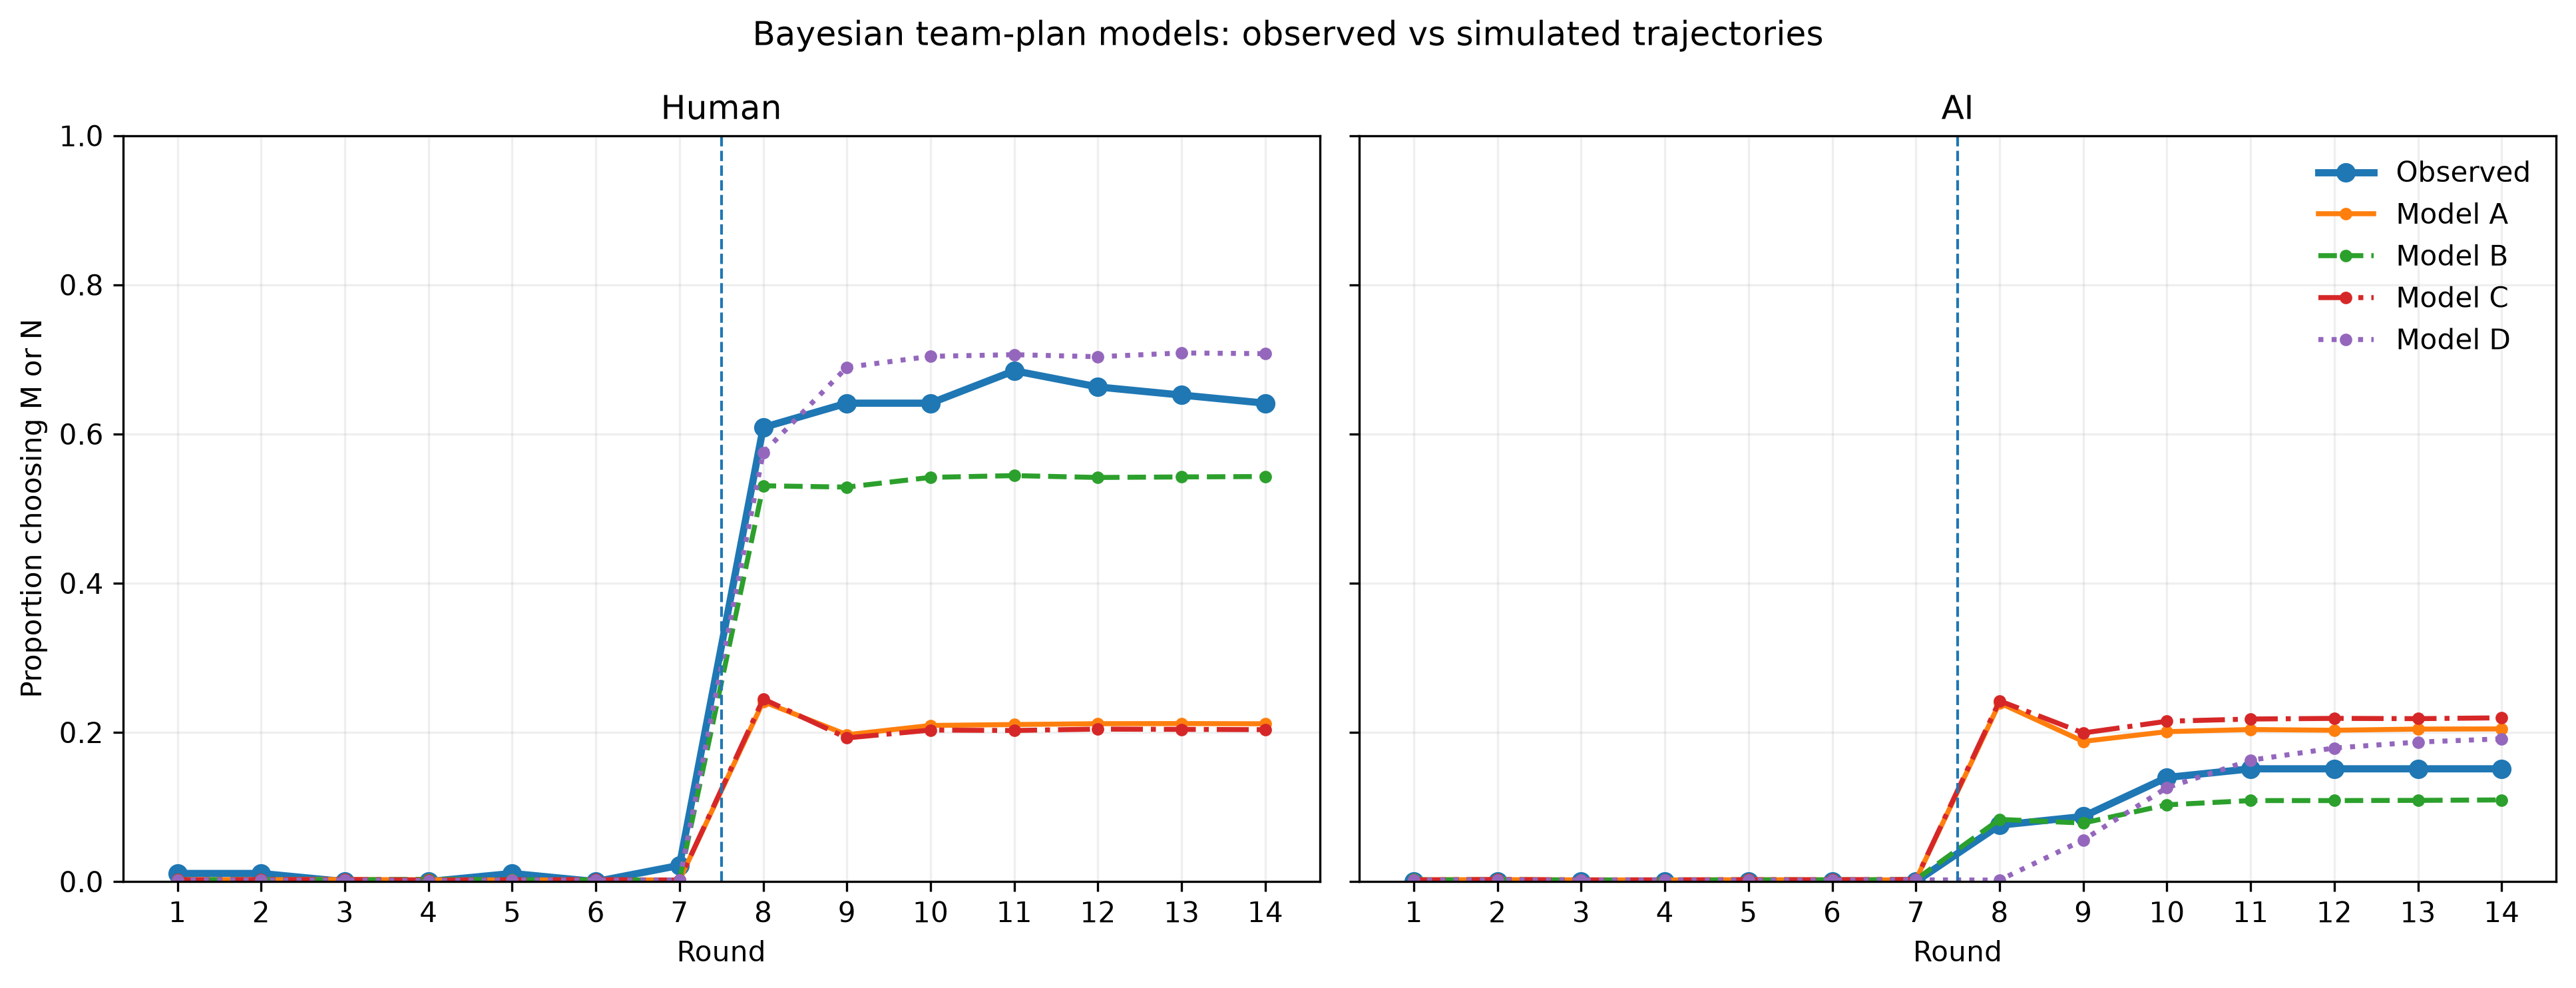

In [22]:
from IPython.display import Image, display
fig_path = Path(OUTPUT_DIR) / "figure_trajectory_14rounds_all_models.png"
if fig_path.exists():
    display(Image(filename=str(fig_path)))
else:
    print(f"Figure not found yet: {fig_path}")

In [23]:
import pandas as pd

recovery = pd.read_csv(
    "team_plan_notebook_outputs/model_D_parameter_recovery_summary.csv"
)

recovery

,parameter,r,true_sd,estimate_sd,bias,MAE,RMSE
0,hH,0.610569,0.081512,0.122562,-0.020599,0.077330,0.099451
1,hA,0.435719,0.000072,0.000257,0.000119,0.000197,0.000264
2,p_loH,0.486248,0.088525,0.128893,-0.023529,0.088515,0.117929
3,p_hiH,0.988258,0.058444,0.066238,-0.006922,0.012169,0.014127
4,p_loA,0.577700,0.053948,0.110750,-0.011826,0.072613,0.091720
5,p_hiA,0.351381,0.000086,0.003762,-0.002167,0.002286,0.004316
6,epsilon,0.859927,0.009614,0.009826,0.000971,0.004714,0.005239


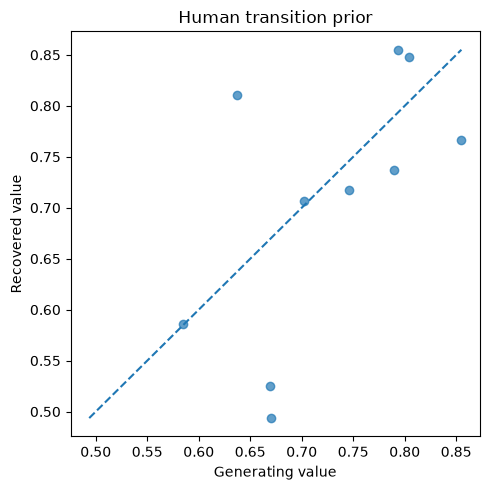

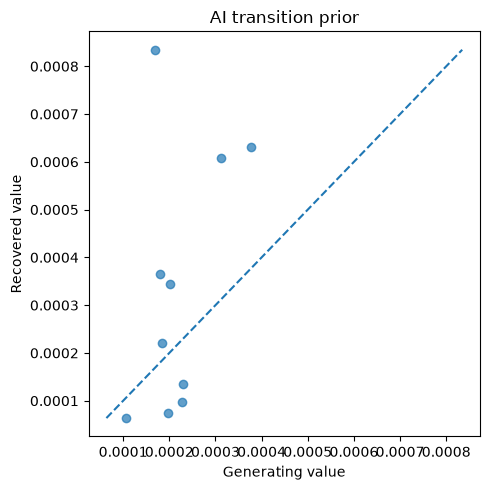

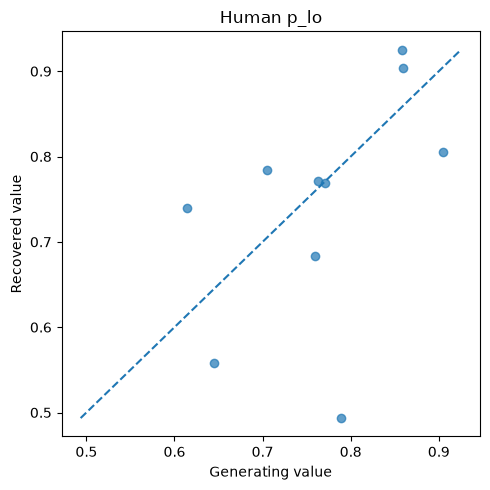

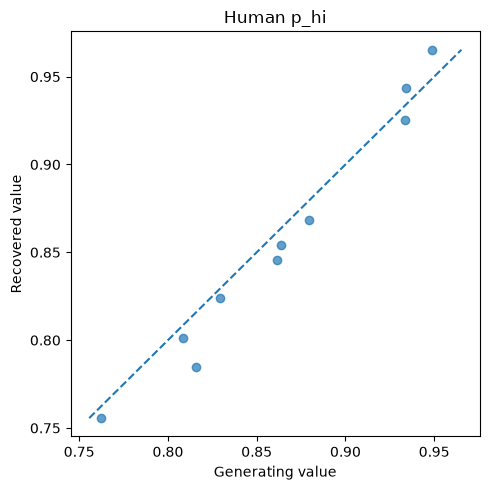

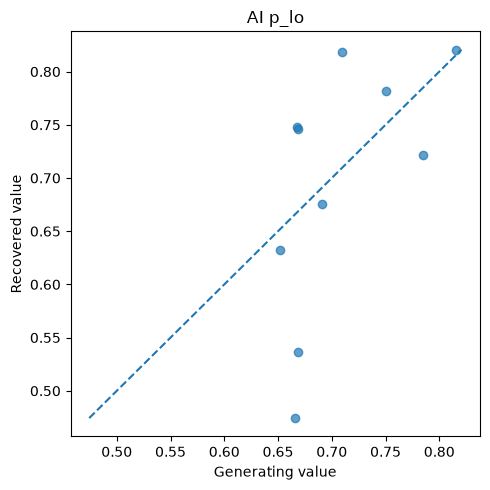

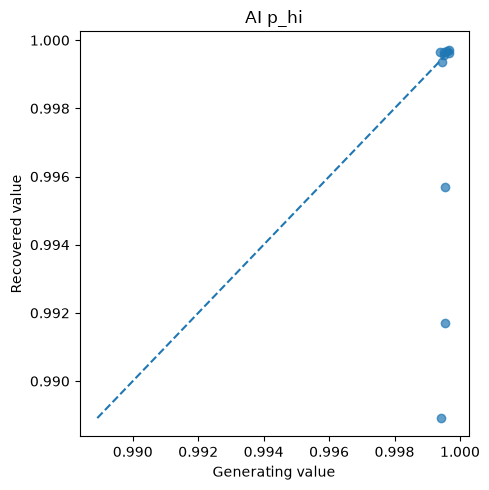

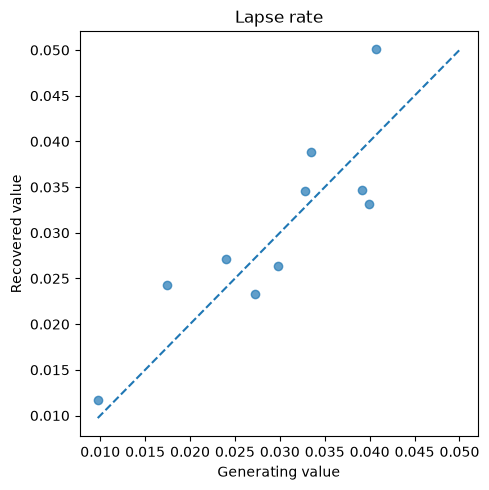

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

rec = pd.read_csv(
    "team_plan_notebook_outputs/model_D_parameter_recovery.csv"
)

params = [
    ("hH", "Human transition prior"),
    ("hA", "AI transition prior"),
    ("p_loH", "Human p_lo"),
    ("p_hiH", "Human p_hi"),
    ("p_loA", "AI p_lo"),
    ("p_hiA", "AI p_hi"),
    ("epsilon", "Lapse rate"),
]

for param, title in params:
    true_col = f"true_{param}"
    est_col = f"est_{param}"

    fig, ax = plt.subplots(figsize=(5, 5))

    ax.scatter(
        rec[true_col],
        rec[est_col],
        alpha=0.7
    )

    lo = min(rec[true_col].min(), rec[est_col].min())
    hi = max(rec[true_col].max(), rec[est_col].max())

    ax.plot([lo, hi], [lo, hi], linestyle="--")

    ax.set_xlabel("Generating value")
    ax.set_ylabel("Recovered value")
    ax.set_title(title)

    fig.tight_layout()

    fig.savefig(
        f"team_plan_notebook_outputs/recovery_{param}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

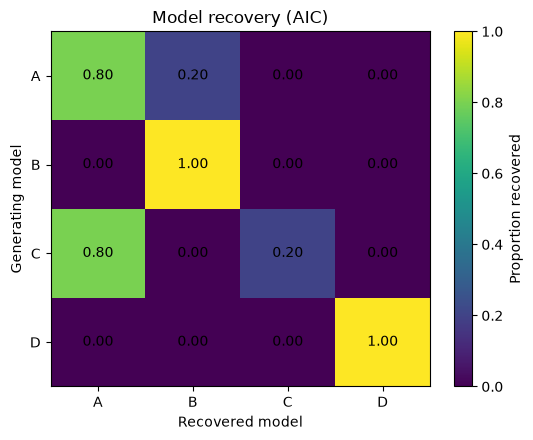

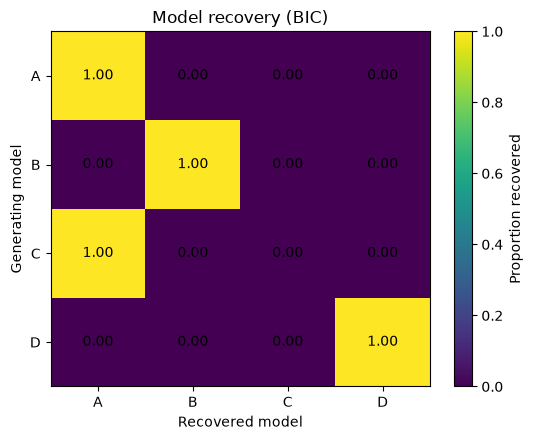

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

for criterion in ["AIC", "BIC"]:

    mat = pd.read_csv(
        f"team_plan_notebook_outputs/model_recovery_{criterion}.csv",
        index_col=0
    )

    fig, ax = plt.subplots(figsize=(5.5, 4.5))

    im = ax.imshow(mat.values, aspect="auto", vmin=0, vmax=1)

    ax.set_xticks(range(len(mat.columns)))
    ax.set_xticklabels(mat.columns)

    ax.set_yticks(range(len(mat.index)))
    ax.set_yticklabels(mat.index)

    ax.set_xlabel("Recovered model")
    ax.set_ylabel("Generating model")
    ax.set_title(f"Model recovery ({criterion})")

    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(
                j, i,
                f"{mat.iloc[i, j]:.2f}",
                ha="center",
                va="center"
            )

    fig.colorbar(im, ax=ax, label="Proportion recovered")

    fig.tight_layout()

    fig.savefig(
        f"team_plan_notebook_outputs/model_recovery_{criterion}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

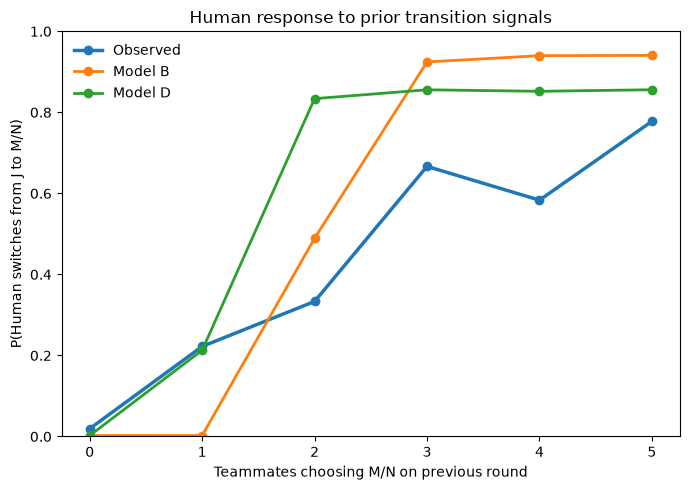

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

sig = pd.read_csv(
    "team_plan_notebook_outputs/human_signal_observed_history.csv"
)

models_to_plot = ["B", "D"]

fig, ax = plt.subplots(figsize=(7, 5))

obs = (
    sig[["signal", "observed_rate", "n"]]
    .drop_duplicates()
    .sort_values("signal")
)

ax.plot(
    obs["signal"],
    obs["observed_rate"],
    marker="o",
    linewidth=2.5,
    label="Observed"
)

for model in models_to_plot:
    d = sig[sig["model"] == model].sort_values("signal")

    ax.plot(
        d["signal"],
        d["predicted_rate"],
        marker="o",
        linewidth=2,
        label=f"Model {model}"
    )

ax.set_xlabel("Teammates choosing M/N on previous round")
ax.set_ylabel("P(Human switches from J to M/N)")
ax.set_ylim(0, 1)
ax.set_xticks(sorted(obs["signal"].unique()))
ax.set_title("Human response to prior transition signals")
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(
    "team_plan_notebook_outputs/human_signal_diagnostic_supplement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
# ============================================================
# BROAD-RANGE PARAMETER RECOVERY FOR MODEL D
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Assumes these already exist from the main notebook:
# groups
# fits
# fit_model
# simulate_postchange_group
# encode_parameters
# DEFAULT_BOUNDS
# PARAM_NAMES
#
# The existing simulator generates the same group compositions as the
# empirical data, which is what we want for recovery. The model's current
# simulation function implements the recent-evidence architecture.
# See existing notebook simulation/recovery code.


def sample_broad_D_parameters(rng):
    """
    Sample Model D parameters broadly across the admissible space.

    Important:
    - h values vary over nearly their full range.
    - p_lo values vary broadly.
    - p_hi >= p_lo by construction.
    - epsilon varies across a plausible broad range.

    We avoid exactly 0/1 to keep logits numerically stable.
    """

    hH = rng.uniform(0.01, 0.99)
    hA = rng.uniform(0.01, 0.99)

    # Broad response-function range.
    p_loH = rng.uniform(0.03, 0.90)
    p_loA = rng.uniform(0.03, 0.90)

    # Conditional sampling enforces monotonicity p_hi >= p_lo.
    p_hiH = rng.uniform(p_loH + 0.02, 0.995)
    p_hiA = rng.uniform(p_loA + 0.02, 0.995)

    # Lapse broad enough to test recovery without making most datasets noise.
    epsilon = rng.uniform(0.001, 0.15)

    return {
        "hH": hH,
        "hA": hA,
        "p_loH": p_loH,
        "p_hiH": p_hiH,
        "p_loA": p_loA,
        "p_hiA": p_hiA,
        "epsilon": epsilon,
    }


def broad_parameter_recovery_D(
    groups,
    n_rep=100,
    n_starts=8,
    maxiter=2500,
    seed=20260820,
    bounds=DEFAULT_BOUNDS,
):
    """
    Broad parameter recovery for Model D.

    Crucially, the optimizer is NOT initialized at the true generating
    parameter vector.
    """

    rng = np.random.default_rng(seed)

    # Use empirical D solution only as one generic warm start.
    # This is allowable because it contains no information about the
    # synthetic generating parameters.
    empirical_theta = np.asarray(fits["D"]["theta"], dtype=float)

    rows = []

    for rep in range(n_rep):

        # ----------------------------------------------------
        # 1. Draw broad generating parameters
        # ----------------------------------------------------
        true_p = sample_broad_D_parameters(rng)

        # ----------------------------------------------------
        # 2. Simulate a dataset with the empirical group structure
        # ----------------------------------------------------
        sim_counts = np.stack([
            simulate_postchange_group(gr, true_p, rng)
            for gr in groups
        ])

        # ----------------------------------------------------
        # 3. Recover parameters
        #
        # DO NOT warm-start at the true parameters.
        # ----------------------------------------------------
        rr, est_p = fit_model(
            model="D",
            counts=sim_counts,
            architecture="recent",
            bounds=bounds,
            n_starts=n_starts,
            seed=seed + 10000 + rep,
            maxiter=maxiter,
            warm_starts=[empirical_theta],
            include_base_with_warm=True,
            jitter_scale=1.0,
        )

        row = {
            "rep": rep + 1,
            "NLL": float(rr.fun),
            "converged": bool(rr.success),
        }

        for name in [
            "hH", "hA",
            "p_loH", "p_hiH",
            "p_loA", "p_hiA",
            "epsilon"
        ]:
            row[f"true_{name}"] = true_p[name]
            row[f"est_{name}"] = est_p[name]

        rows.append(row)

        if (rep + 1) % 10 == 0:
            print(f"Broad recovery: {rep + 1}/{n_rep}")

    raw = pd.DataFrame(rows)

    # --------------------------------------------------------
    # Recovery summary
    # --------------------------------------------------------
    summary_rows = []

    parameter_names = [
        "hH", "hA",
        "p_loH", "p_hiH",
        "p_loA", "p_hiA",
        "epsilon"
    ]

    for name in parameter_names:

        x = raw[f"true_{name}"].to_numpy()
        y = raw[f"est_{name}"].to_numpy()

        error = y - x

        summary_rows.append({
            "parameter": name,
            "r": np.corrcoef(x, y)[0, 1],
            "true_sd": np.std(x),
            "estimate_sd": np.std(y),
            "bias": np.mean(error),
            "MAE": np.mean(np.abs(error)),
            "RMSE": np.sqrt(np.mean(error ** 2)),
        })

    summary = pd.DataFrame(summary_rows)

    return raw, summary

In [28]:
[x for x in ["df", "groups", "counts", "fits"] if x in globals()]

[]

In [30]:
print(DATA_PATH)
print(DATA_PATH.exists())

/Users/calypsocalcott/Downloads/name_game_combined_human_llm_mixed.csv


AttributeError: 'str' object has no attribute 'exists'

In [31]:
from pathlib import Path

DATA_PATH = Path(
    "/Users/calypsocalcott/Downloads/name_game_combined_human_llm_mixed.csv"
)

print(DATA_PATH)
print(DATA_PATH.exists())

/Users/calypsocalcott/Downloads/name_game_combined_human_llm_mixed.csv
True


In [32]:
df, groups, meta, counts = load_and_validate_data(DATA_PATH)

print(f"{len(groups)} groups")
print(f"{int(counts.sum())} post-change choices")
display(meta.groupby("condition").size())

44 groups
1848 post-change choices


condition
2H + 4LLM     5
3H + 3LLM     6
4H + 2LLM     7
Human         6
LLM          20
dtype: int64

In [33]:
fits, fit_summary = fit_all_models(
    counts,
    architecture="recent",
    bounds=DEFAULT_BOUNDS,
    n_starts=12,
    maxiter=2500,
    seed=20260820,
)

display(
    fit_summary[
        ["model", "NLL", "AIC", "BIC",
         "hH", "hA",
         "p_loH", "p_hiH",
         "p_loA", "p_hiA",
         "epsilon"]
    ]
)

  recent     Model A: NLL=698.917 (0.2s)
  recent     Model B: NLL=652.842 (0.1s)
  recent     Model C: NLL=698.225 (0.2s)
  recent     Model D: NLL=645.173 (0.3s)


,model,NLL,AIC,BIC,hH,hA,p_loH,p_hiH,p_loA,p_hiA,epsilon
0,D,645.173330,1304.346661,1342.999675,0.699468,0.000207,0.794477,0.878082,0.704844,0.999539,0.027682
1,B,652.841846,1315.683692,1343.292988,0.574232,0.086408,0.954155,0.967984,0.954155,0.967984,0.030645
2,A,698.916636,1405.833273,1427.920710,0.258156,0.258156,0.955781,0.960371,0.955781,0.960371,0.029805
3,C,698.224671,1408.449341,1441.580497,0.256351,0.256351,0.958458,0.958500,0.947224,0.980419,0.030475


In [34]:
broad_rec_raw, broad_rec_summary = broad_parameter_recovery_D(
    groups=groups,
    n_rep=50,
    n_starts=8,
    maxiter=2500,
    seed=20260820,
)

display(broad_rec_summary.round(3))

Broad recovery: 10/50
Broad recovery: 20/50
Broad recovery: 30/50
Broad recovery: 40/50
Broad recovery: 50/50


,parameter,r,true_sd,estimate_sd,bias,MAE,RMSE
0,hH,0.922,0.267,0.256,-0.029,0.068,0.108
1,hA,0.982,0.284,0.295,0.013,0.044,0.058
2,p_loH,0.947,0.241,0.239,0.006,0.062,0.078
3,p_hiH,0.990,0.213,0.217,0.003,0.018,0.030
4,p_loA,0.894,0.228,0.233,-0.003,0.074,0.106
5,p_hiA,0.997,0.226,0.230,-0.001,0.016,0.019
6,epsilon,0.988,0.039,0.039,0.001,0.005,0.006


In [35]:
# ============================================================
# POST-CHANGE REALIZED PAYOFF ANALYSIS
# ============================================================
# Question:
# Does attempting to transition from J to M/N actually produce
# more realized points than simply remaining coordinated on J?
#
# Rounds 8-14:
#   coordinated on J   -> 10 points per player
#   coordinated on M/N -> 20 points per player
#   anything else      -> 0 points per player
#
# Perfectly staying on J for all 7 post-change rounds = 70 points.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

J_BASELINE = len(POST_ROUNDS) * PAYOFF_J   # 7 * 10 = 70


# ------------------------------------------------------------
# 1. Collapse participant-level data to group x round
# ------------------------------------------------------------

post = df[df["round"].isin(POST_ROUNDS)].copy()

group_round_payoff = (
    post
    .groupby(["group_key", "condition", "round"], as_index=False)
    .agg(
        n_players=("actor_id", "size"),
        n_unique_choices=("choice_category", "nunique"),
        first_choice=("choice_category", "first"),
        n_J=("choice_category", lambda x: (x == "J").sum()),
        n_M=("choice_category", lambda x: (x == "M").sum()),
        n_N=("choice_category", lambda x: (x == "N").sum()),
    )
)

# A group earns points only if all six players choose the same
# payoff-relevant letter.
group_round_payoff["coordinated_J"] = (
    group_round_payoff["n_J"] == GROUP_SIZE
)

group_round_payoff["coordinated_M"] = (
    group_round_payoff["n_M"] == GROUP_SIZE
)

group_round_payoff["coordinated_N"] = (
    group_round_payoff["n_N"] == GROUP_SIZE
)

group_round_payoff["coordinated_MN"] = (
    group_round_payoff["coordinated_M"] |
    group_round_payoff["coordinated_N"]
)

group_round_payoff["coordinated"] = (
    group_round_payoff["coordinated_J"] |
    group_round_payoff["coordinated_MN"]
)

group_round_payoff["payoff"] = np.select(
    [
        group_round_payoff["coordinated_J"],
        group_round_payoff["coordinated_MN"],
    ],
    [
        PAYOFF_J,
        PAYOFF_MN,
    ],
    default=0.0,
)

group_round_payoff["outcome"] = np.select(
    [
        group_round_payoff["coordinated_J"],
        group_round_payoff["coordinated_MN"],
    ],
    [
        "Coordinated J",
        "Coordinated M/N",
    ],
    default="Miscoordinated",
)

display(group_round_payoff.head(15))

,group_key,condition,round,n_players,n_unique_choices,first_choice,n_J,n_M,n_N,coordinated_J,coordinated_M,coordinated_N,coordinated_MN,coordinated,payoff,outcome
0,250mt4ay_G10,3H + 3LLM,8,6,3,M,3,2,1,False,False,False,False,False,0.0,Miscoordinated
1,250mt4ay_G10,3H + 3LLM,9,6,2,J,2,4,0,False,False,False,False,False,0.0,Miscoordinated
2,250mt4ay_G10,3H + 3LLM,10,6,2,J,2,4,0,False,False,False,False,False,0.0,Miscoordinated
3,250mt4ay_G10,3H + 3LLM,11,6,1,M,0,6,0,False,True,False,True,True,20.0,Coordinated M/N
4,250mt4ay_G10,3H + 3LLM,12,6,1,M,0,6,0,False,True,False,True,True,20.0,Coordinated M/N
5,250mt4ay_G10,3H + 3LLM,13,6,1,M,0,6,0,False,True,False,True,True,20.0,Coordinated M/N
6,250mt4ay_G10,3H + 3LLM,14,6,1,M,0,6,0,False,True,False,True,True,20.0,Coordinated M/N
7,250mt4ay_G11,4H + 2LLM,8,6,3,N,3,1,2,False,False,False,False,False,0.0,Miscoordinated
8,250mt4ay_G11,4H + 2LLM,9,6,3,M,3,1,2,False,False,False,False,False,0.0,Miscoordinated
9,250mt4ay_G11,4H + 2LLM,10,6,2,N,4,0,2,False,False,False,False,False,0.0,Miscoordinated


In [37]:
# ------------------------------------------------------------
# 2. Total realized payoff in rounds 8-14
# ------------------------------------------------------------

group_payoff = (
    group_round_payoff
    .groupby(["group_key", "condition"], as_index=False)
    .agg(
        total_postchange_points=("payoff", "sum"),
        n_rounds_J=("coordinated_J", "sum"),
        n_rounds_MN=("coordinated_MN", "sum"),
        n_rounds_miscoordinated=("coordinated", lambda x: (~x).sum()),
    )
)

group_payoff["gain_vs_stay_J"] = (
    group_payoff["total_postchange_points"] - J_BASELINE
)

group_payoff["beats_stay_J"] = (
    group_payoff["total_postchange_points"] > J_BASELINE
)

group_payoff["equals_stay_J"] = (
    group_payoff["total_postchange_points"] == J_BASELINE
)

print(f"Stay-on-J benchmark: {J_BASELINE:.0f} points")
display(group_payoff.sort_values("total_postchange_points", ascending=False))

Stay-on-J benchmark: 70 points


,group_key,condition,total_postchange_points,n_rounds_J,n_rounds_MN,n_rounds_miscoordinated,gain_vs_stay_J,beats_stay_J,equals_stay_J
38,swkdlthb_G18,4H + 2LLM,120.0,0,6,1,50.0,True,False
42,swkdlthb_G6,4H + 2LLM,100.0,0,5,2,30.0,True,False
41,swkdlthb_G3,2H + 4LLM,100.0,0,5,2,30.0,True,False
40,swkdlthb_G21,2H + 4LLM,100.0,0,5,2,30.0,True,False
9,jzn8r3ih_G2,Human,100.0,0,5,2,30.0,True,False
6,250mt4ay_G7,4H + 2LLM,90.0,1,4,2,20.0,True,False
0,250mt4ay_G10,3H + 3LLM,80.0,0,4,3,10.0,True,False
10,jzn8r3ih_G3,Human,80.0,0,4,3,10.0,True,False
37,swkdlthb_G14,2H + 4LLM,80.0,0,4,3,10.0,True,False
11,jzn8r3ih_G4,Human,80.0,0,4,3,10.0,True,False


In [38]:
# ------------------------------------------------------------
# 3. Payoff by team composition
# ------------------------------------------------------------

condition_payoff_summary = (
    group_payoff
    .groupby("condition")
    .agg(
        n_groups=("group_key", "nunique"),
        mean_points=("total_postchange_points", "mean"),
        median_points=("total_postchange_points", "median"),
        sd_points=("total_postchange_points", "std"),
        min_points=("total_postchange_points", "min"),
        max_points=("total_postchange_points", "max"),
        mean_gain_vs_J=("gain_vs_stay_J", "mean"),
        prop_beating_J=("beats_stay_J", "mean"),
        prop_equal_J=("equals_stay_J", "mean"),
    )
    .reset_index()
)

display(condition_payoff_summary.round(3))

,condition,n_groups,mean_points,median_points,sd_points,min_points,max_points,mean_gain_vs_J,prop_beating_J,prop_equal_J
0,2H + 4LLM,5,78.000,80.0,24.900,40.0,100.0,8.000,0.600,0.200
1,3H + 3LLM,6,60.000,65.0,20.976,30.0,80.0,-10.000,0.333,0.167
2,4H + 2LLM,7,70.000,80.0,37.417,20.0,120.0,0.000,0.571,0.000
3,Human,6,51.667,60.0,41.191,0.0,100.0,-18.333,0.500,0.000
4,LLM,20,65.500,70.0,6.048,50.0,70.0,-4.500,0.000,0.600


In [39]:
# ============================================================
# DECOMPOSE THE COST OF TRANSITION
# ============================================================

# Assumes these already exist:
#   group_round_payoff
#   group_payoff
#   post
#   GROUP_SIZE
#   J_BASELINE = 70


# ------------------------------------------------------------
# 1. Add round-level number of players attempting M/N
# ------------------------------------------------------------

mn_round = (
    post
    .assign(chose_MN=post["choice_category"].isin(["M", "N"]))
    .groupby(["group_key", "condition", "round"], as_index=False)
    .agg(
        n_MN=("chose_MN", "sum"),
        n_J=("choice_category", lambda x: (x == "J").sum()),
    )
)

gr = group_round_payoff.merge(
    mn_round,
    on=["group_key", "condition", "round"],
    how="left",
    suffixes=("", "_attempt")
)

# Any attempt to leave J
gr["transition_attempt"] = gr["n_MN"] > 0

# Attempt occurred but group did not successfully coordinate on M/N
gr["failed_transition_round"] = (
    gr["transition_attempt"] &
    ~gr["coordinated_MN"]
)

# Complete failure to coordinate on any payoff-paying equilibrium
gr["miscoordination_round"] = ~gr["coordinated"]

display(gr.head(20))

,group_key,condition,round,n_players,n_unique_choices,first_choice,n_J,n_M,n_N,coordinated_J,...,coordinated_N,coordinated_MN,coordinated,payoff,outcome,n_MN,n_J_attempt,transition_attempt,failed_transition_round,miscoordination_round
0,250mt4ay_G10,3H + 3LLM,8,6,3,M,3,2,1,False,...,False,False,False,0.0,Miscoordinated,3,3,True,True,True
1,250mt4ay_G10,3H + 3LLM,9,6,2,J,2,4,0,False,...,False,False,False,0.0,Miscoordinated,4,2,True,True,True
2,250mt4ay_G10,3H + 3LLM,10,6,2,J,2,4,0,False,...,False,False,False,0.0,Miscoordinated,4,2,True,True,True
3,250mt4ay_G10,3H + 3LLM,11,6,1,M,0,6,0,False,...,False,True,True,20.0,Coordinated M/N,6,0,True,False,False
4,250mt4ay_G10,3H + 3LLM,12,6,1,M,0,6,0,False,...,False,True,True,20.0,Coordinated M/N,6,0,True,False,False
5,250mt4ay_G10,3H + 3LLM,13,6,1,M,0,6,0,False,...,False,True,True,20.0,Coordinated M/N,6,0,True,False,False
6,250mt4ay_G10,3H + 3LLM,14,6,1,M,0,6,0,False,...,False,True,True,20.0,Coordinated M/N,6,0,True,False,False
7,250mt4ay_G11,4H + 2LLM,8,6,3,N,3,1,2,False,...,False,False,False,0.0,Miscoordinated,3,3,True,True,True
8,250mt4ay_G11,4H + 2LLM,9,6,3,M,3,1,2,False,...,False,False,False,0.0,Miscoordinated,3,3,True,True,True
9,250mt4ay_G11,4H + 2LLM,10,6,2,N,4,0,2,False,...,False,False,False,0.0,Miscoordinated,2,4,True,True,True


In [41]:
trajectory_rows = []

for (group_key, condition), g in gr.groupby(
    ["group_key", "condition"]
):
    g = g.sort_values("round").copy()

    ever_attempted = g["transition_attempt"].any()
    ever_MN = g["coordinated_MN"].any()

    first_attempt = (
        g.loc[g["transition_attempt"], "round"].min()
        if ever_attempted else np.nan
    )

    final = g.iloc[-1]

    final_J = bool(final["coordinated_J"])
    final_MN = bool(final["coordinated_MN"])

    # Did J coordination reappear after an attempted transition?
    recovered_J = False
    if ever_attempted:
        recovered_J = (
            g.loc[
                g["round"] > first_attempt,
                "coordinated_J"
            ].any()
        )

    if not ever_attempted:
        trajectory = "Stable precedent"

    elif ever_MN and final_MN:
        trajectory = "Successful sustained transition"

    elif ever_MN and not final_MN:
        trajectory = "Unstable transition"

    elif (not ever_MN) and recovered_J:
        trajectory = "Failed transition, recovered J"

    else:
        trajectory = "Failed transition, no recovery"

    trajectory_rows.append({
        "group_key": group_key,
        "condition": condition,
        "trajectory": trajectory,

        "ever_attempted_MN": ever_attempted,
        "ever_reached_MN": ever_MN,

        "final_state": (
            "M/N" if final_MN
            else "J" if final_J
            else "Miscoordinated"
        ),

        "n_MN_rounds": int(g["coordinated_MN"].sum()),
        "n_J_rounds": int(g["coordinated_J"].sum()),
        "n_miscoord_rounds": int(
            g["miscoordination_round"].sum()
        ),

        "total_points": g["payoff"].sum(),
    })

trajectory_df = pd.DataFrame(trajectory_rows)

trajectory_df["gain_vs_J"] = (
    trajectory_df["total_points"] - J_BASELINE
)

display(
    trajectory_df.sort_values(
        ["condition", "trajectory", "group_key"]
    )
)

,group_key,condition,trajectory,ever_attempted_MN,ever_reached_MN,final_state,n_MN_rounds,n_J_rounds,n_miscoord_rounds,total_points,gain_vs_J
43,swkdlthb_G8,2H + 4LLM,"Failed transition, recovered J",True,False,J,0,4,3,40.0,-30.0
35,swkdlthb_G11,2H + 4LLM,Stable precedent,False,False,J,0,7,0,70.0,0.0
37,swkdlthb_G14,2H + 4LLM,Successful sustained transition,True,True,M/N,4,0,3,80.0,10.0
40,swkdlthb_G21,2H + 4LLM,Successful sustained transition,True,True,M/N,5,0,2,100.0,30.0
41,swkdlthb_G3,2H + 4LLM,Successful sustained transition,True,True,M/N,5,0,2,100.0,30.0
2,250mt4ay_G2,3H + 3LLM,"Failed transition, recovered J",True,False,J,0,3,4,30.0,-40.0
7,250mt4ay_G8,3H + 3LLM,"Failed transition, recovered J",True,False,J,0,4,3,40.0,-30.0
39,swkdlthb_G20,3H + 3LLM,"Failed transition, recovered J",True,False,J,0,6,1,60.0,-10.0
4,250mt4ay_G5,3H + 3LLM,Stable precedent,False,False,J,0,7,0,70.0,0.0
0,250mt4ay_G10,3H + 3LLM,Successful sustained transition,True,True,M/N,4,0,3,80.0,10.0
